In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

# load data

Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data

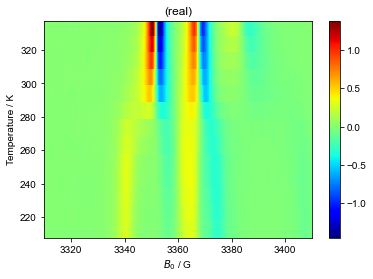

In [2]:
d_cooling = find_file("240226_TEMPOSO4_C10_W3_run1.DSC", exp_type="francklab_esr/romana") #cooling
# I should be able to do the following without the chunk-auto, but then sort freaks out -- this is a bug
d_cooling= d_cooling.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_cooling.reorder('Temperature').sort('Temperature')
d_cooling.pcolor()

## Check field ranges for the three lines

<!-- let's use 300 and 220 K as examples for where the peaks are located in the "high-temp" vs. "low-temp" limits
 -->
RS: I will set above 280 K and below 280 K

## Cooling 

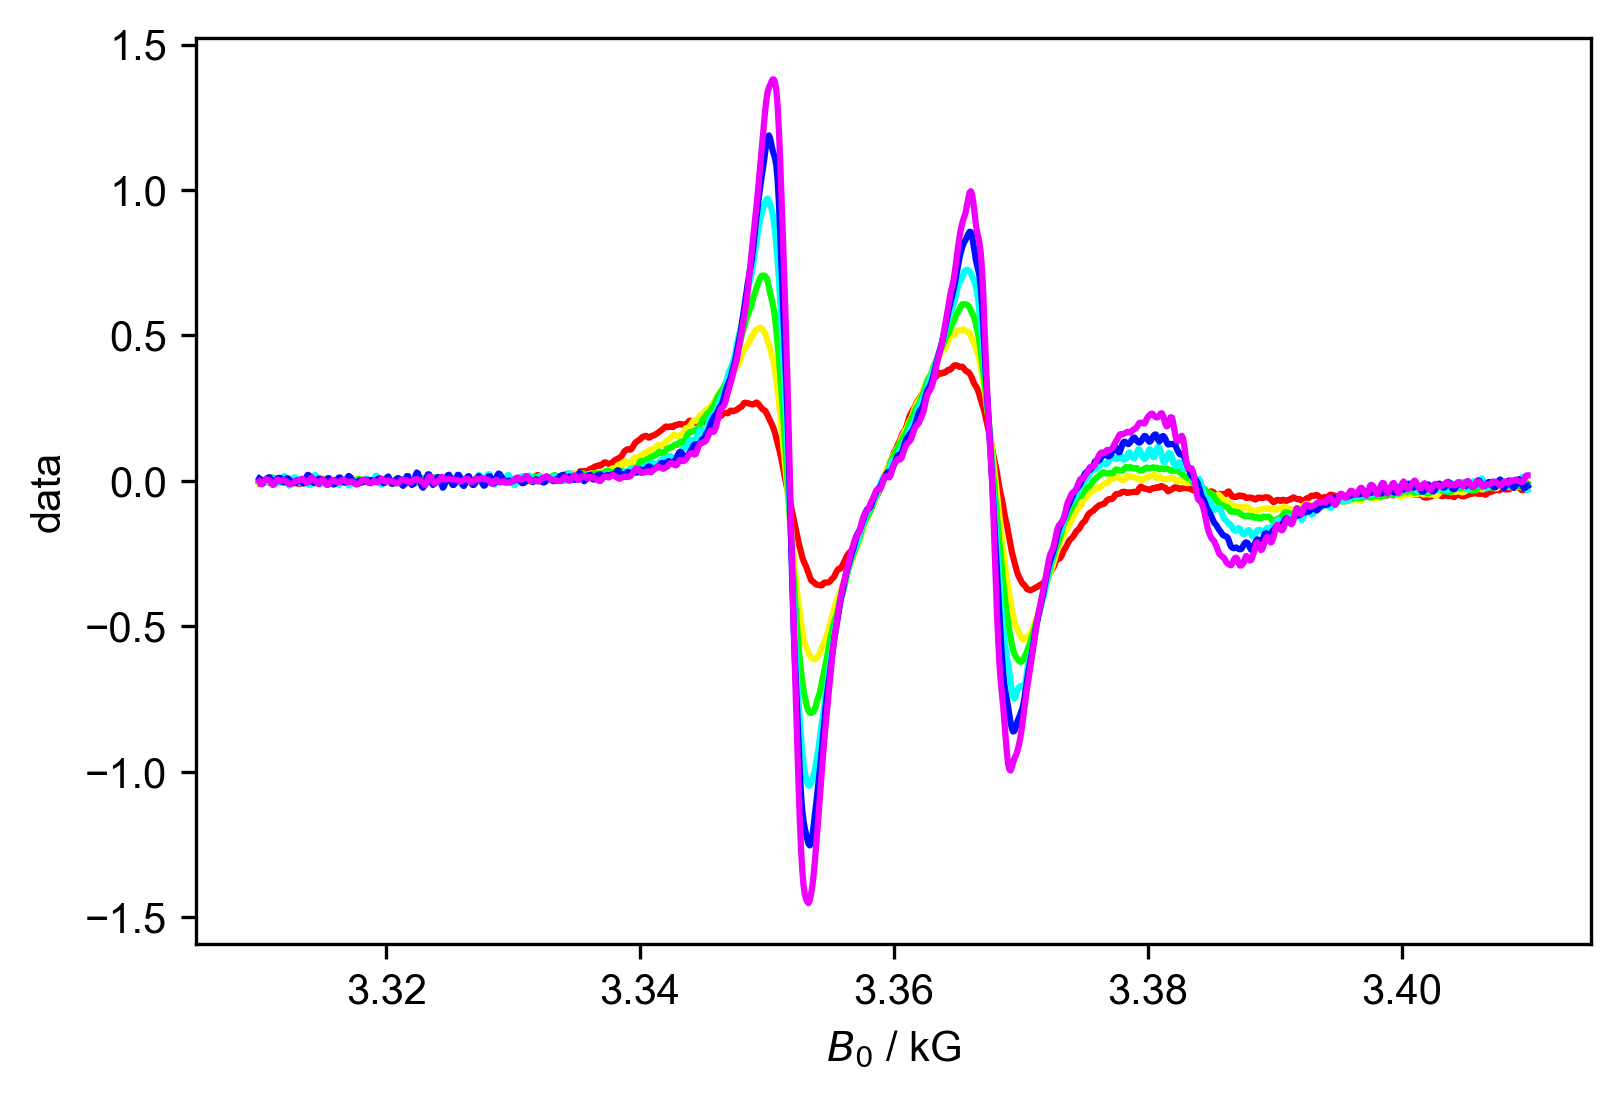

In [3]:
figure(dpi=300)
d_cooling['Temperature':(280,None)]

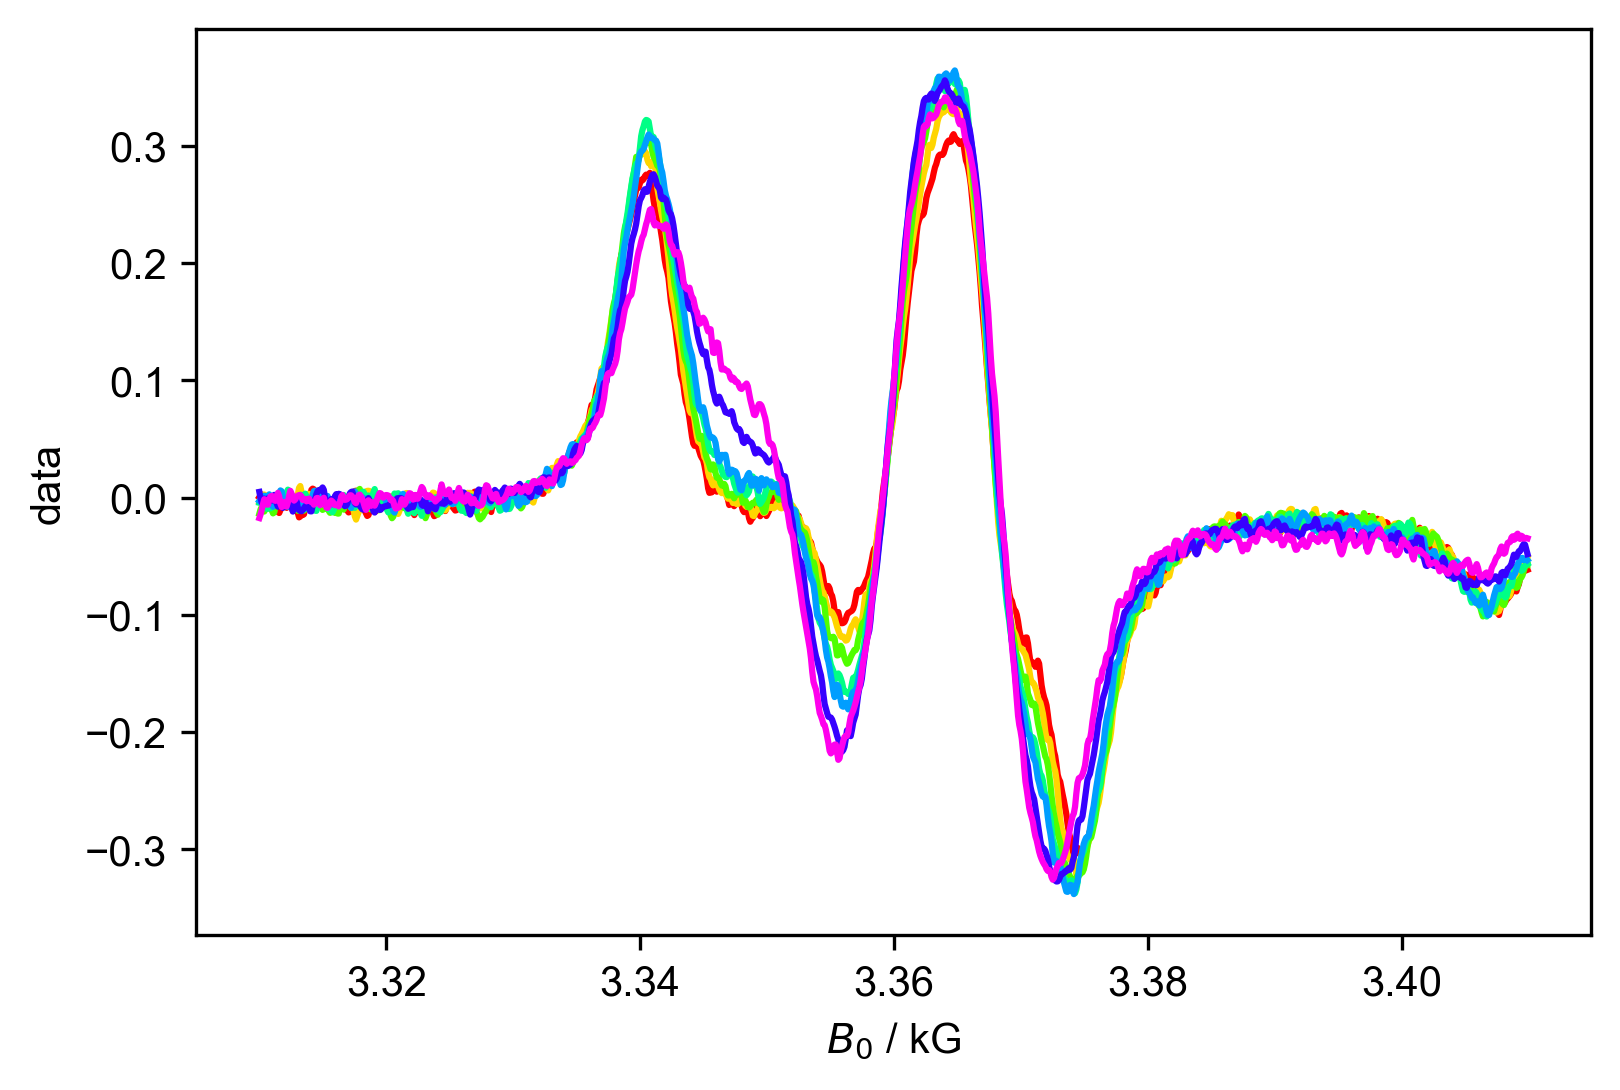

In [4]:
figure(dpi=300)
d_cooling['Temperature':(None,280)]

RS: For above transition, the fields are

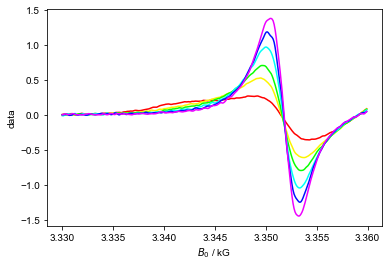

In [5]:
d_cooling['Temperature':(280,None)]['$B_0$':(3330,3360)] # peak A above transition

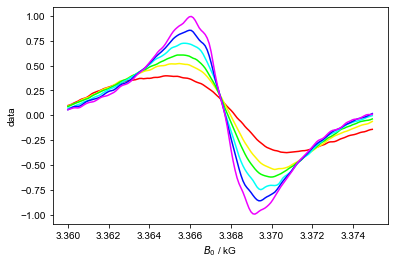

In [6]:
d_cooling['Temperature':(280,None)]['$B_0$':(3360,3375)] # peak B above transition

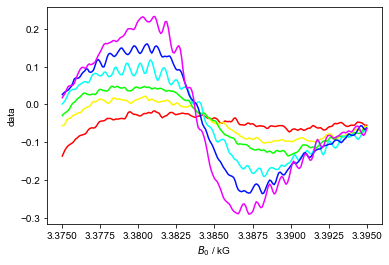

In [7]:
d_cooling['Temperature':(280,None)]['$B_0$':(3375,3395)] # peak C above transition

RS: for below transition the fields are

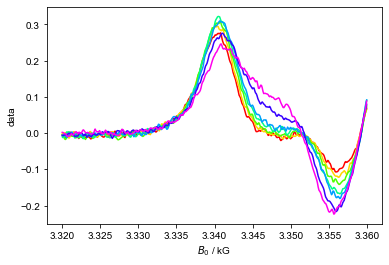

In [8]:
d_cooling['Temperature':(None,280)]['$B_0$':(3320,3360)] # peak A below transition

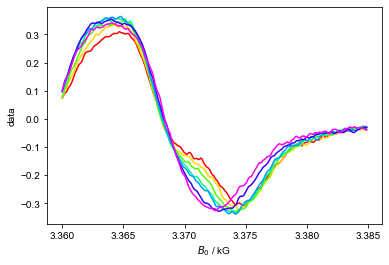

In [9]:
d_cooling['Temperature':(None,280)]['$B_0$':(3360,3385)] # peak B below transition

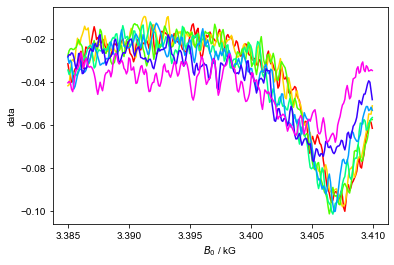

In [10]:
d_cooling['Temperature':(None,280)]['$B_0$':(3385,3410)] # peak C below transition

# Pick the Peaks and Calculate the Correlation times

The first cell here only operates over a limited temperature range.

I'm leaving it to RS to figure out the peak ranges that are needed outside this temperature range, and to
add the appropriate if/else statements on line 15-17 to handle that.

I would duplicate this cell, and then modify it.

Note that you can play with the cells above to figure out what a good range for the lower temperatures would be.

#### RS: below transition 

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.324904018776793e-08


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.344178952909398e-08


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.227854991426719e-08


... (14 outputs left out)

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 2.164905328620604e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.5789897194508207e-09
1: slice peak A
2: slice peak B
3: slice peak C
4: pub_fig



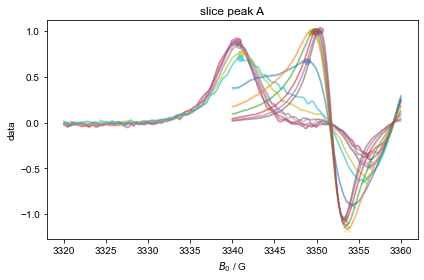

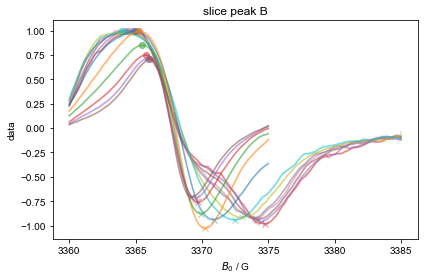

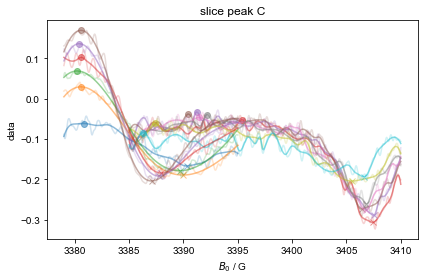

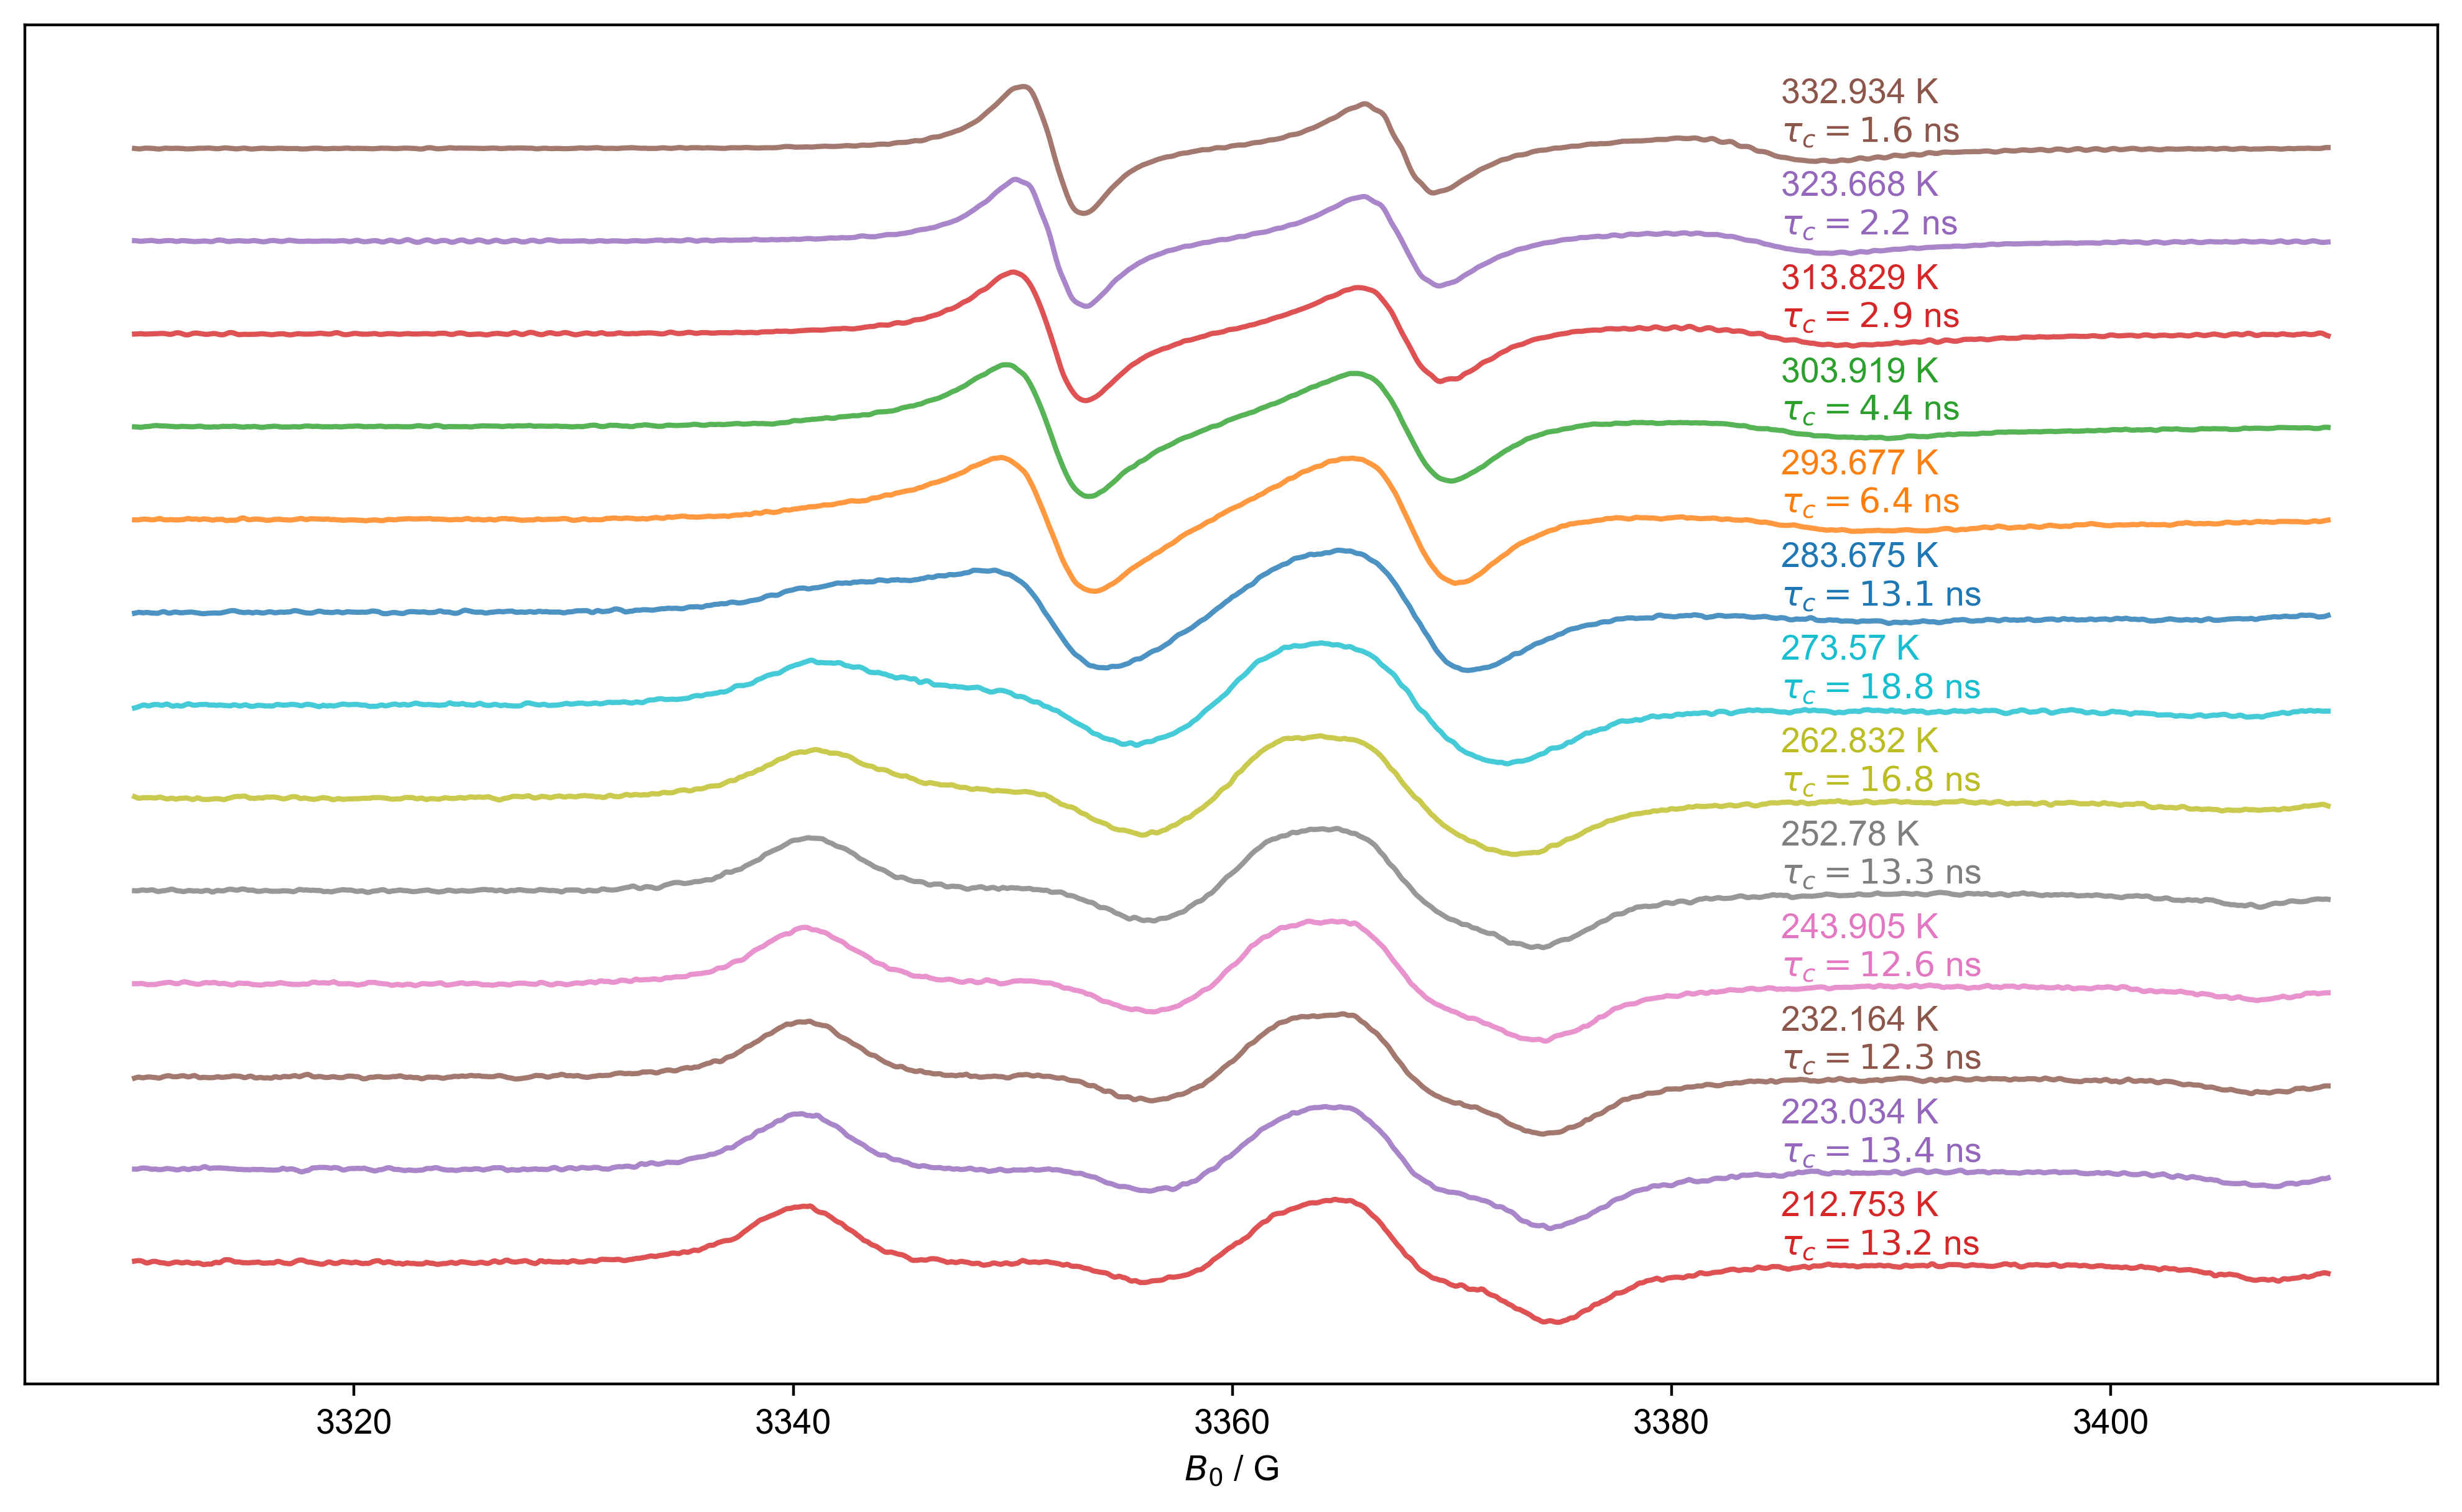

In [12]:
all_data= d_cooling['Temperature':(None,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
correlation_time = {}
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 280:
            peak_A_range = (3340,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3379,3395)
#         elif this_temp >= 263:
            
        else:
            peak_A_range = (3320,3360)
            peak_B_range = (3360,3385)
            peak_C_range = (3385,3410)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=3e-3)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time[label_str] = tau_c 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

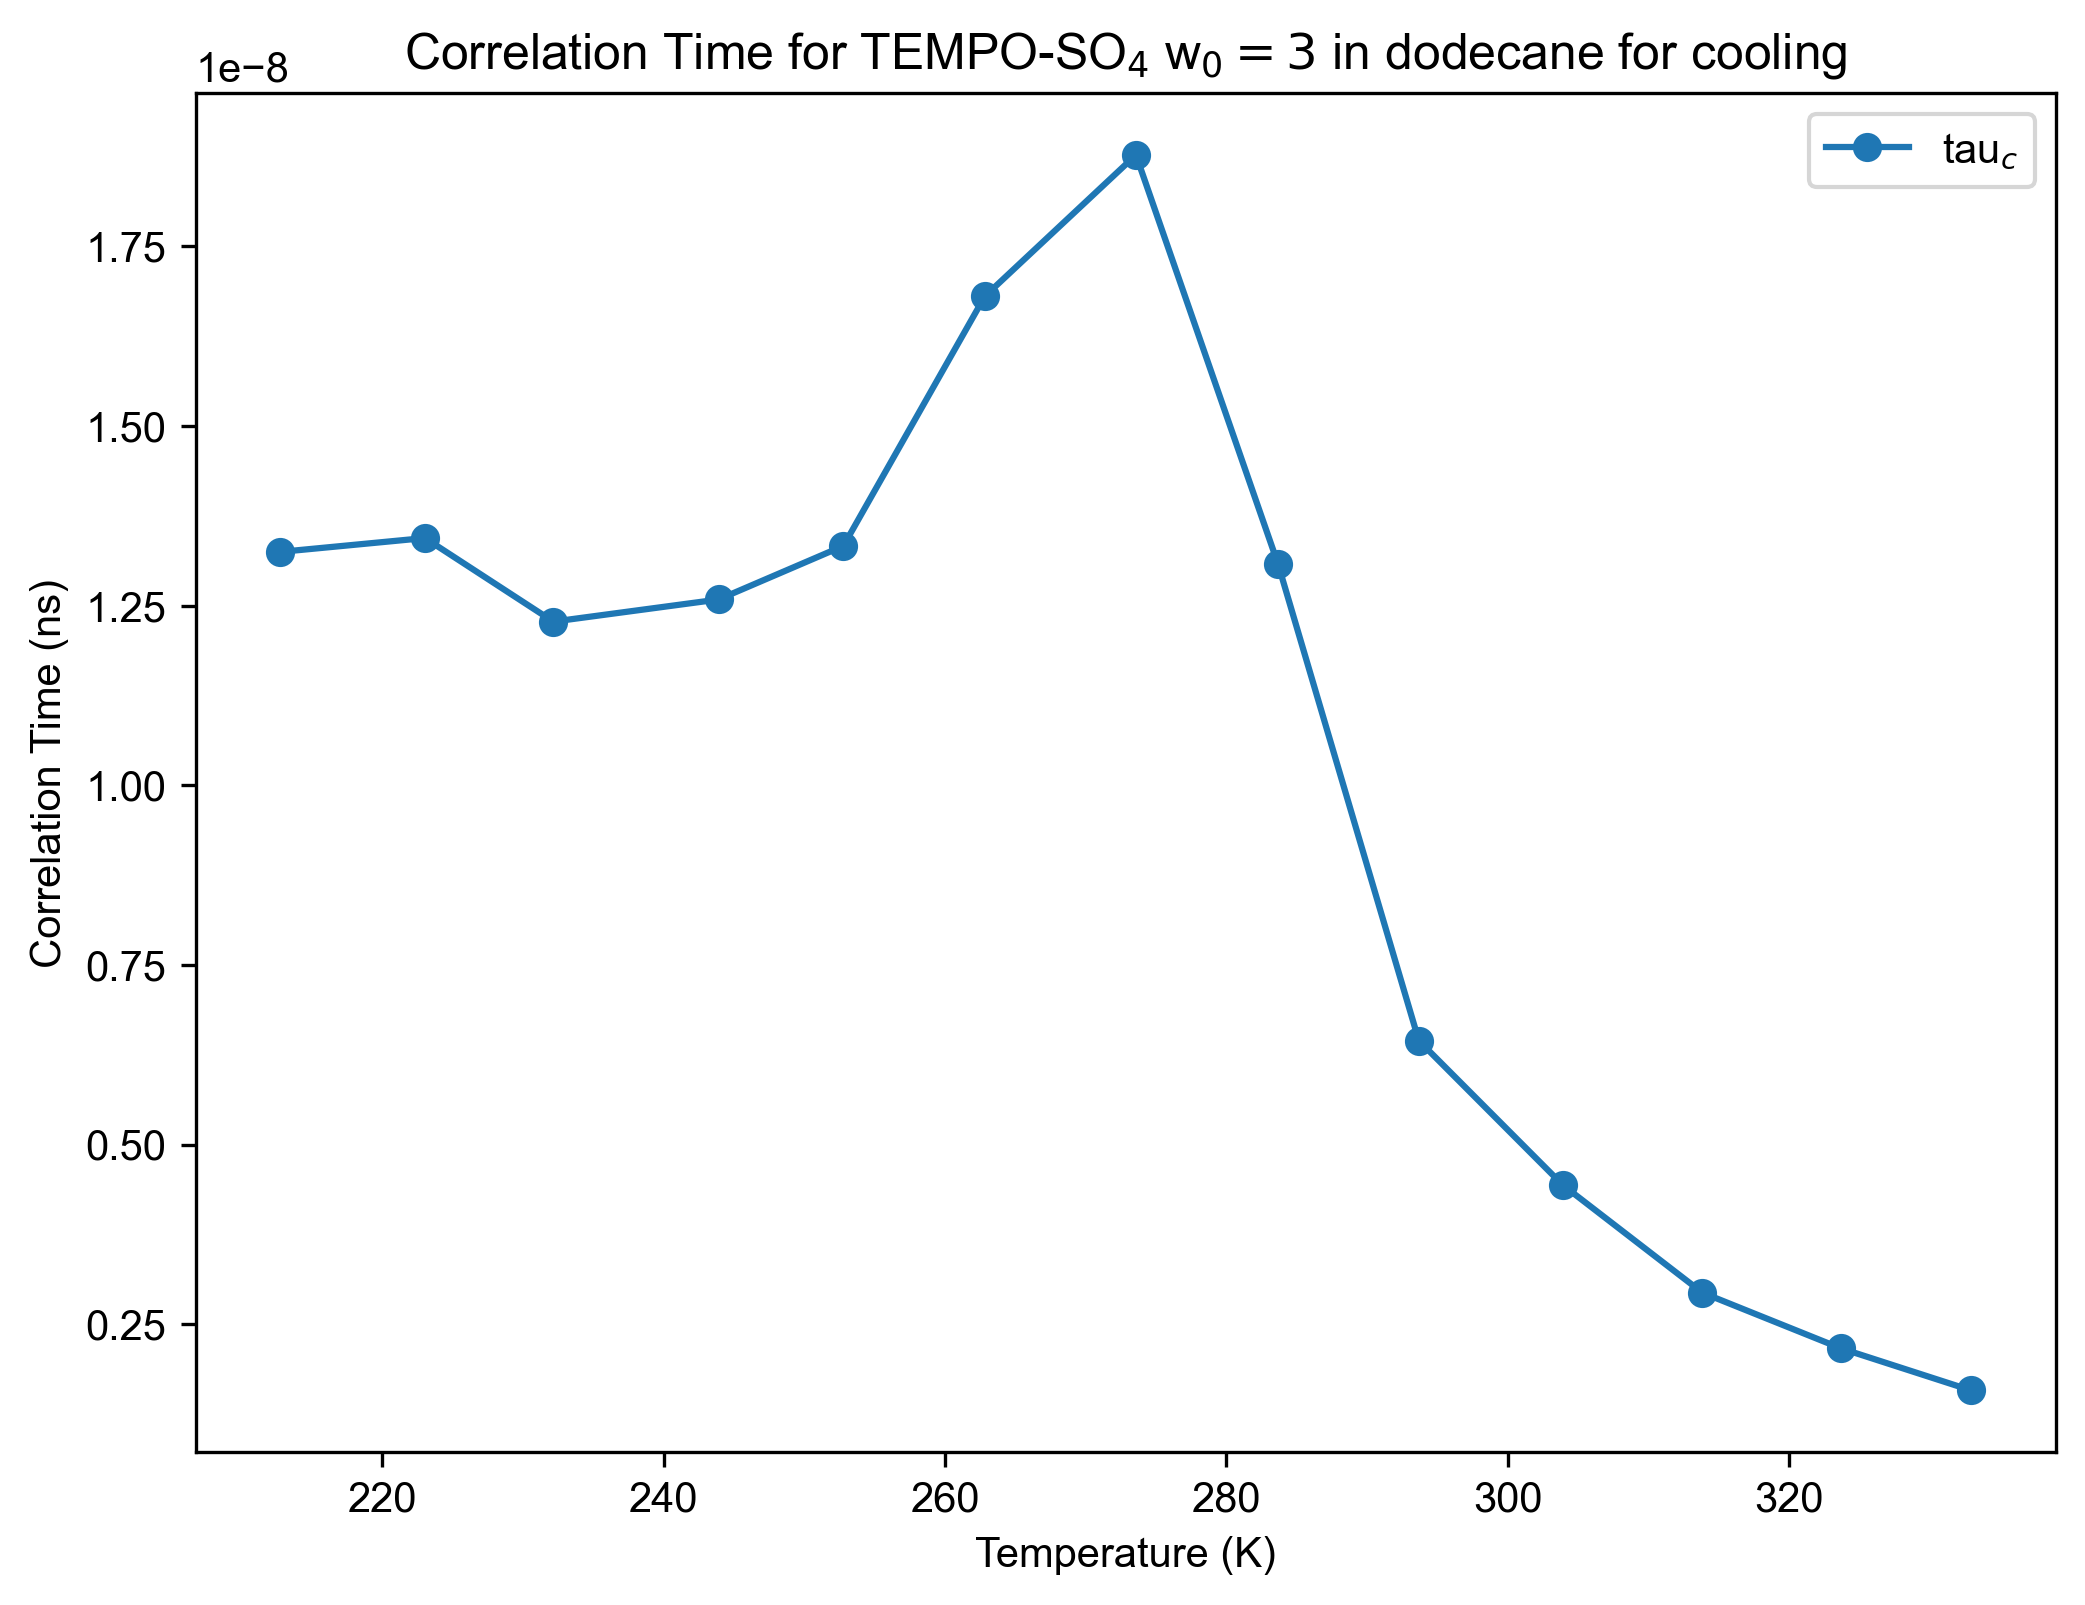

In [13]:
temp= [float(temp) for temp in correlation_time.keys()]
tau= list(correlation_time.values())
figure(dpi=300, figsize=(8,6))
plot(temp, tau, linestyle='-',  marker='o', label="tau$_c$")
legend()
plt.xlabel('Temperature (K)')
plt.ylabel('Correlation Time (ns)')
plt.title('Correlation Time for TEMPO-SO$_4$ w$_0=3$ in dodecane for cooling')
plt.show()

In [14]:
correlation_time

{'212.753': 1.324904018776793e-08,
 '223.034': 1.344178952909398e-08,
 '232.164': 1.227854991426719e-08,
 '243.905': 1.2586614377589818e-08,
 '252.78': 1.3332283736698691e-08,
 '262.832': 1.6806560390507393e-08,
 '273.57': 1.8773614305614453e-08,
 '283.675': 1.3077592936336303e-08,
 '293.677': 6.446673406002674e-09,
 '303.919': 4.435340390679179e-09,
 '313.829': 2.939181095283415e-09,
 '323.668': 2.164905328620604e-09,
 '332.934': 1.5789897194508207e-09}

#### RS: above transition 

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

correlation time is 1.1929839327439971e-08
correlation time is 6.616218927903371e-09
correlation time is 4.4397495918548575e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

correlation time is 2.864365475402895e-09
correlation time is 2.1285119338441666e-09
correlation time is 1.6442038065126611e-09
1: slice peak A
2: slice peak B
3: slice peak C
4: pub_fig



c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

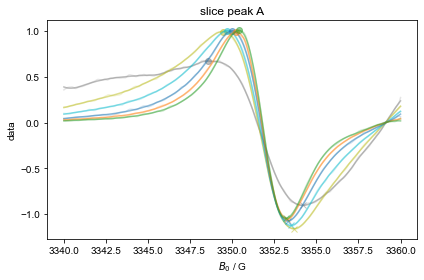

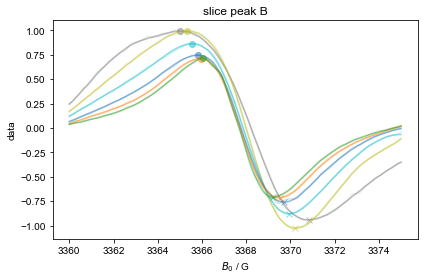

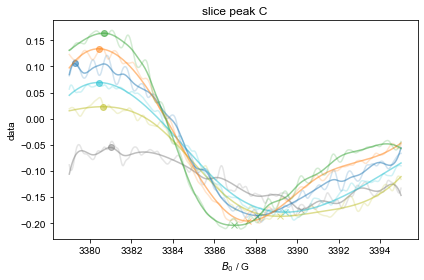

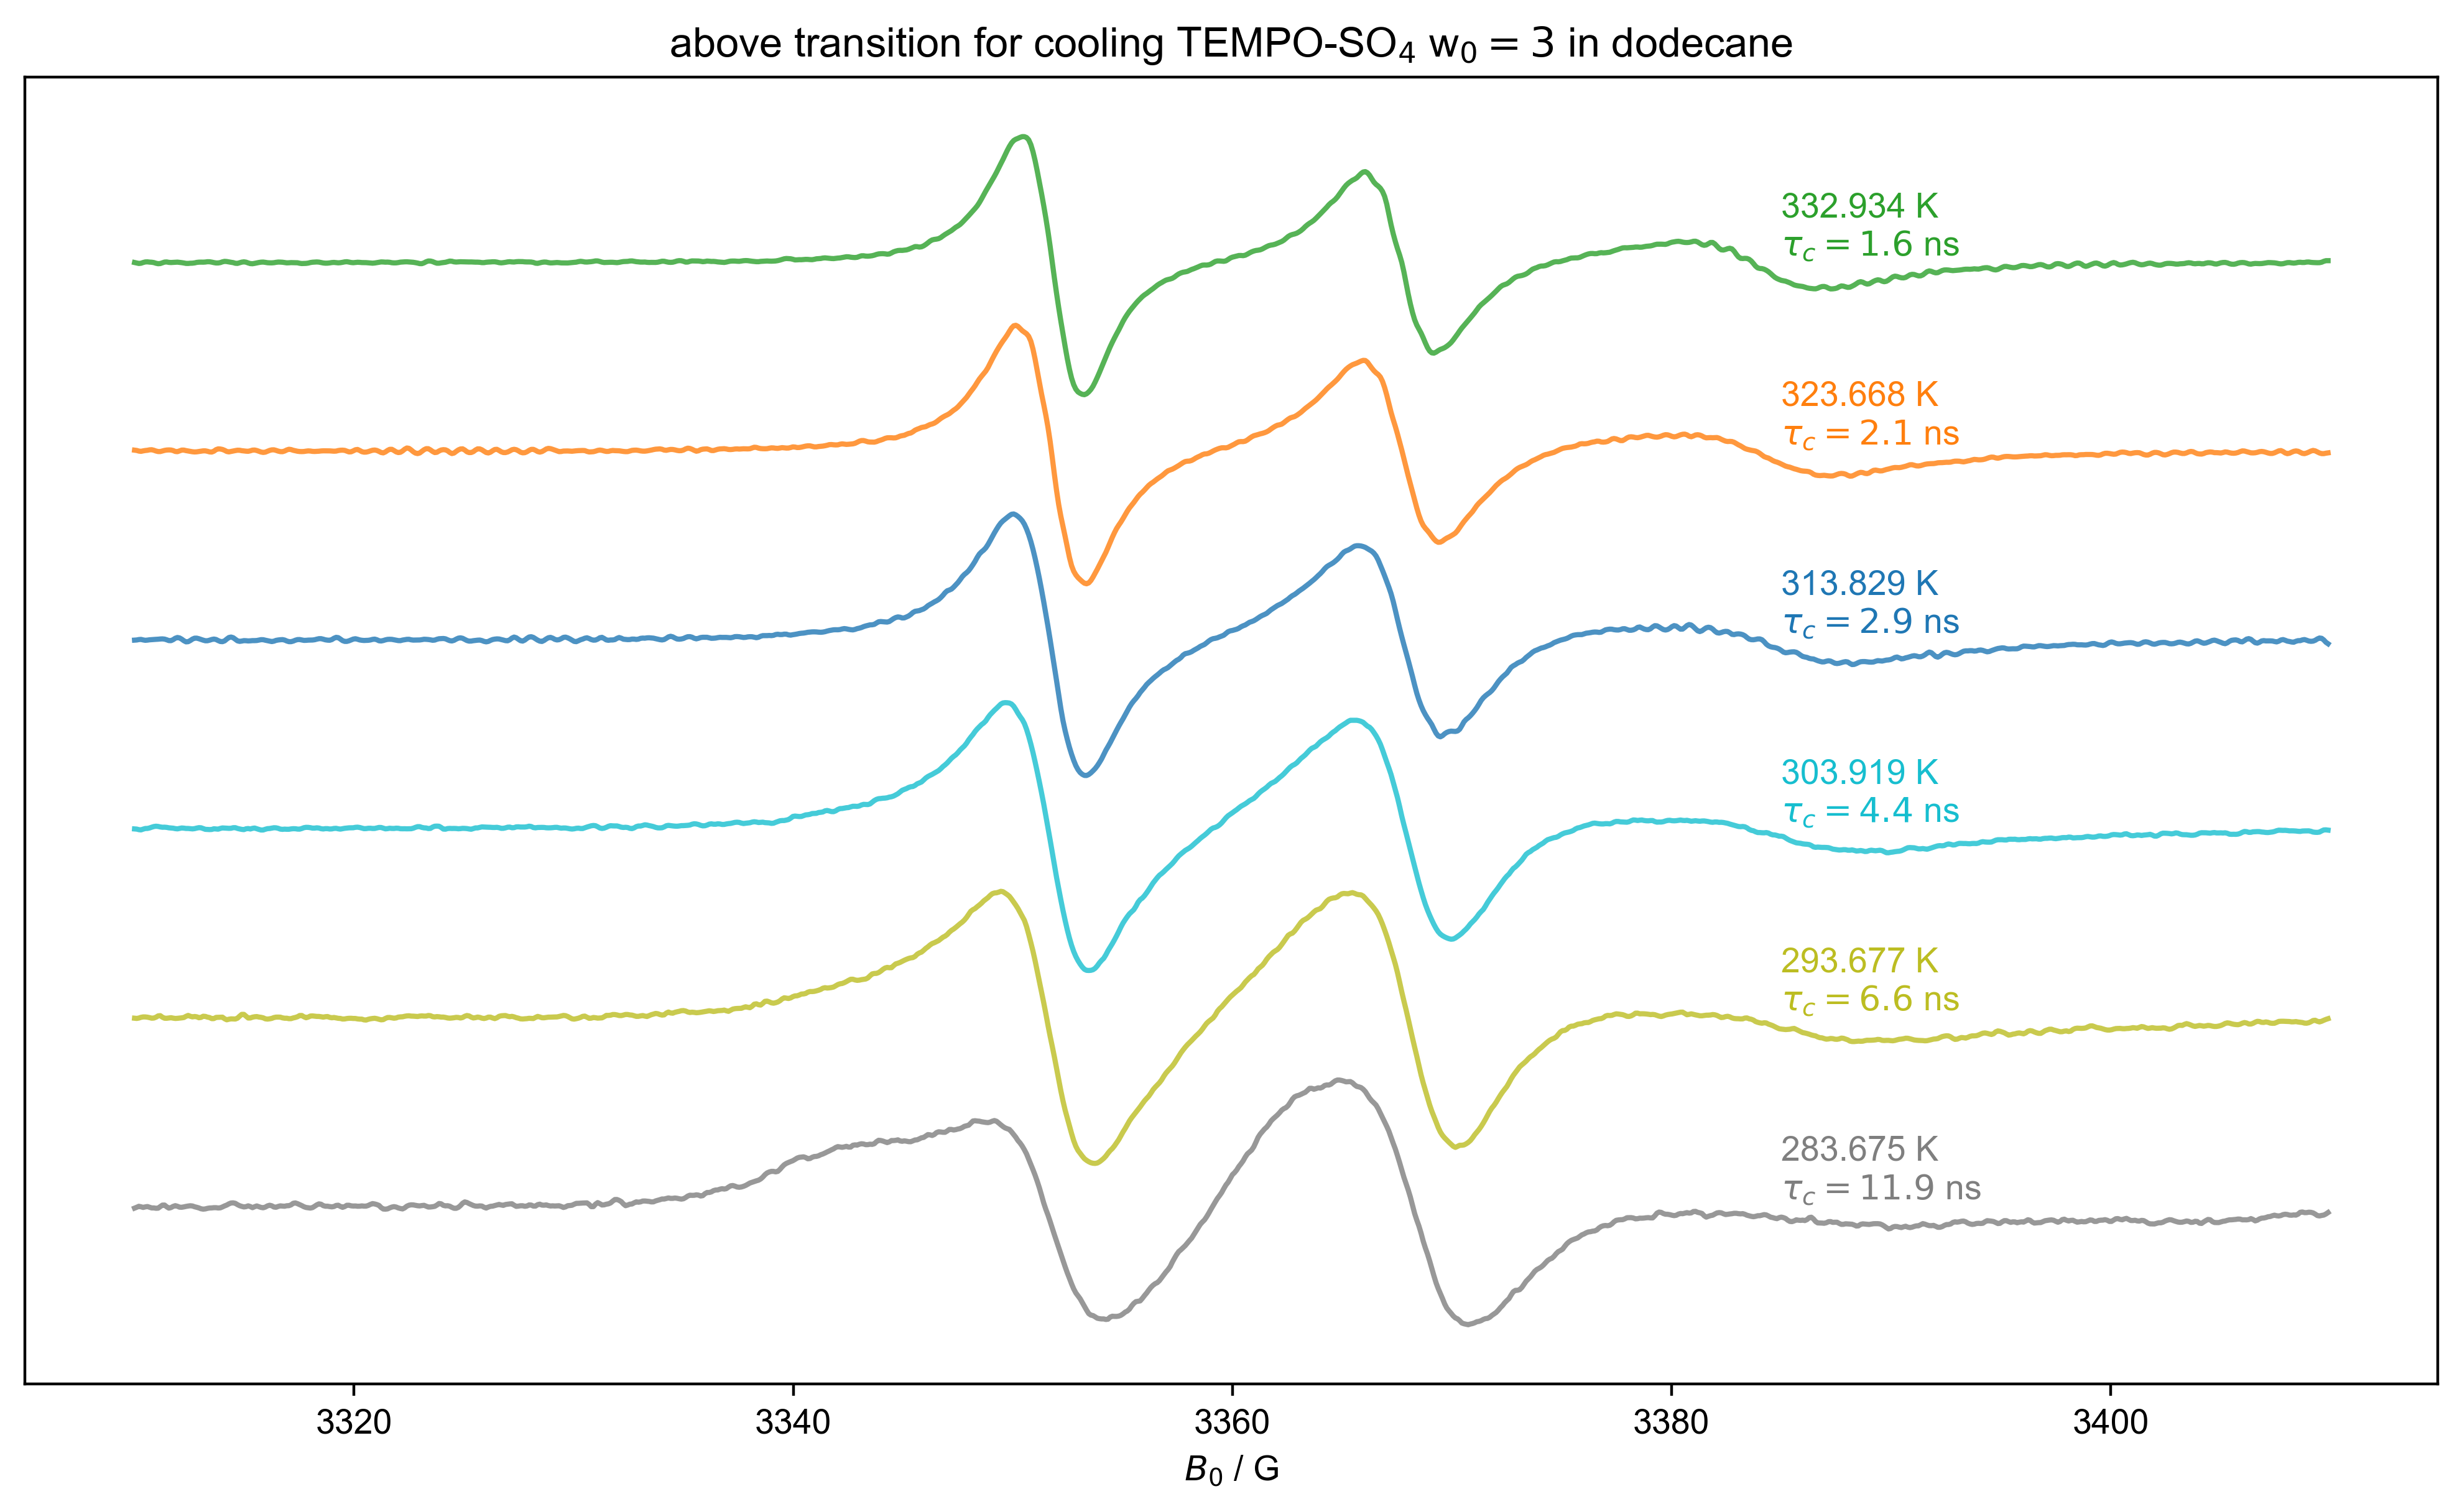

In [14]:
all_data= d_cooling['Temperature':(280,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 280:
            peak_A_range = (3340,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3379,3395)
#         elif this_temp >= 263:
            
        else:
            peak_A_range = (3320,3360)
            peak_B_range = (3360,3385)
            peak_C_range = (3385,3410)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=2e-3)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time[label_str] = tau_c 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('above transition for cooling TEMPO-SO$_4$ w$_0=3$ in dodecane')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [15]:
correlation_time

{'212.753': 1.3395814191123828e-08,
 '223.034': 1.3333854541490703e-08,
 '232.164': 1.2200135997022498e-08,
 '243.905': 1.4366879991130507e-08,
 '252.78': 1.2996122409684641e-08,
 '262.832': 1.568753492741097e-08,
 '273.57': 1.824991618284544e-08,
 '283.675': 1.1929839327439971e-08,
 '293.677': 6.616218927903371e-09,
 '303.919': 4.4397495918548575e-09,
 '313.829': 2.864365475402895e-09,
 '323.668': 2.1285119338441666e-09,
 '332.934': 1.6442038065126611e-09}

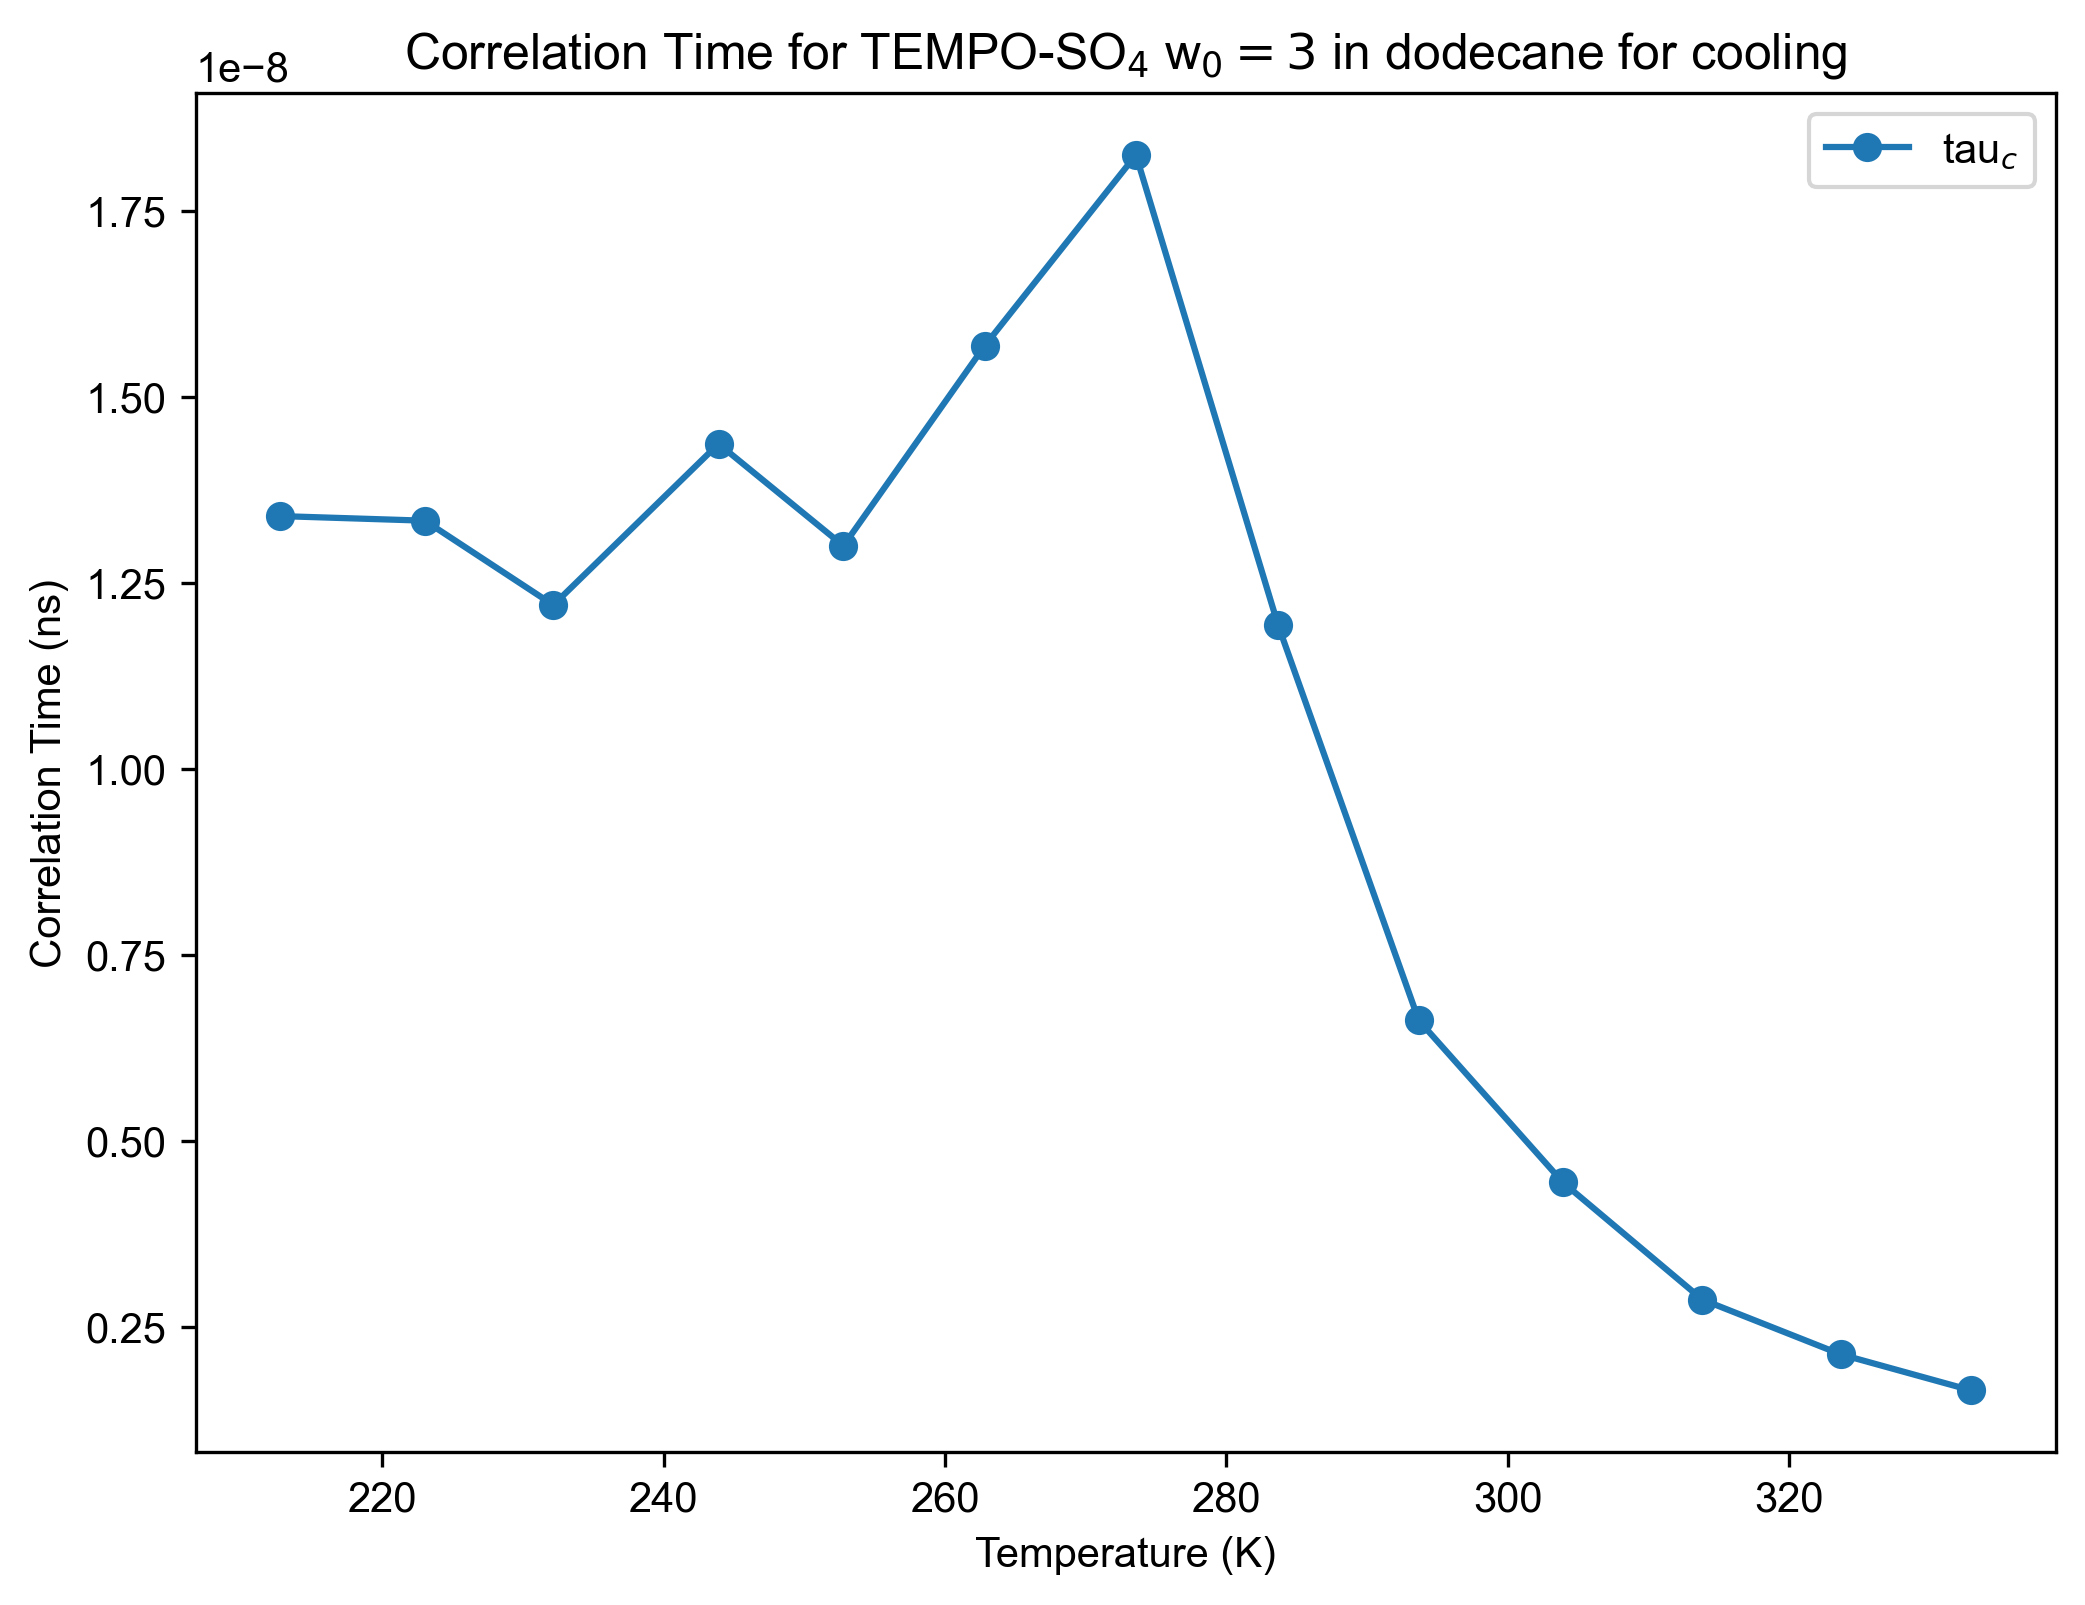

In [16]:
temp= [float(temp) for temp in correlation_time.keys()]
tau= list(correlation_time.values())
figure(dpi=300, figsize=(8,6))
plot(temp, tau, linestyle='-',  marker='o', label="tau$_c$")
legend()
plt.xlabel('Temperature (K)')
plt.ylabel('Correlation Time (ns)')
plt.title('Correlation Time for TEMPO-SO$_4$ w$_0=3$ in dodecane for cooling')
plt.show()

## Reheating 

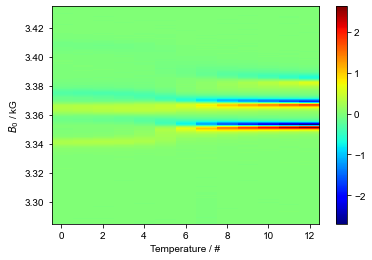

In [15]:
d_reheating = find_file("240226_TEMPOSO4_C10_W3_run2.DSC", exp_type="francklab_esr/romana") #reheating subsequently
d_reheating = d_reheating["harmonic", 0]
d_reheating

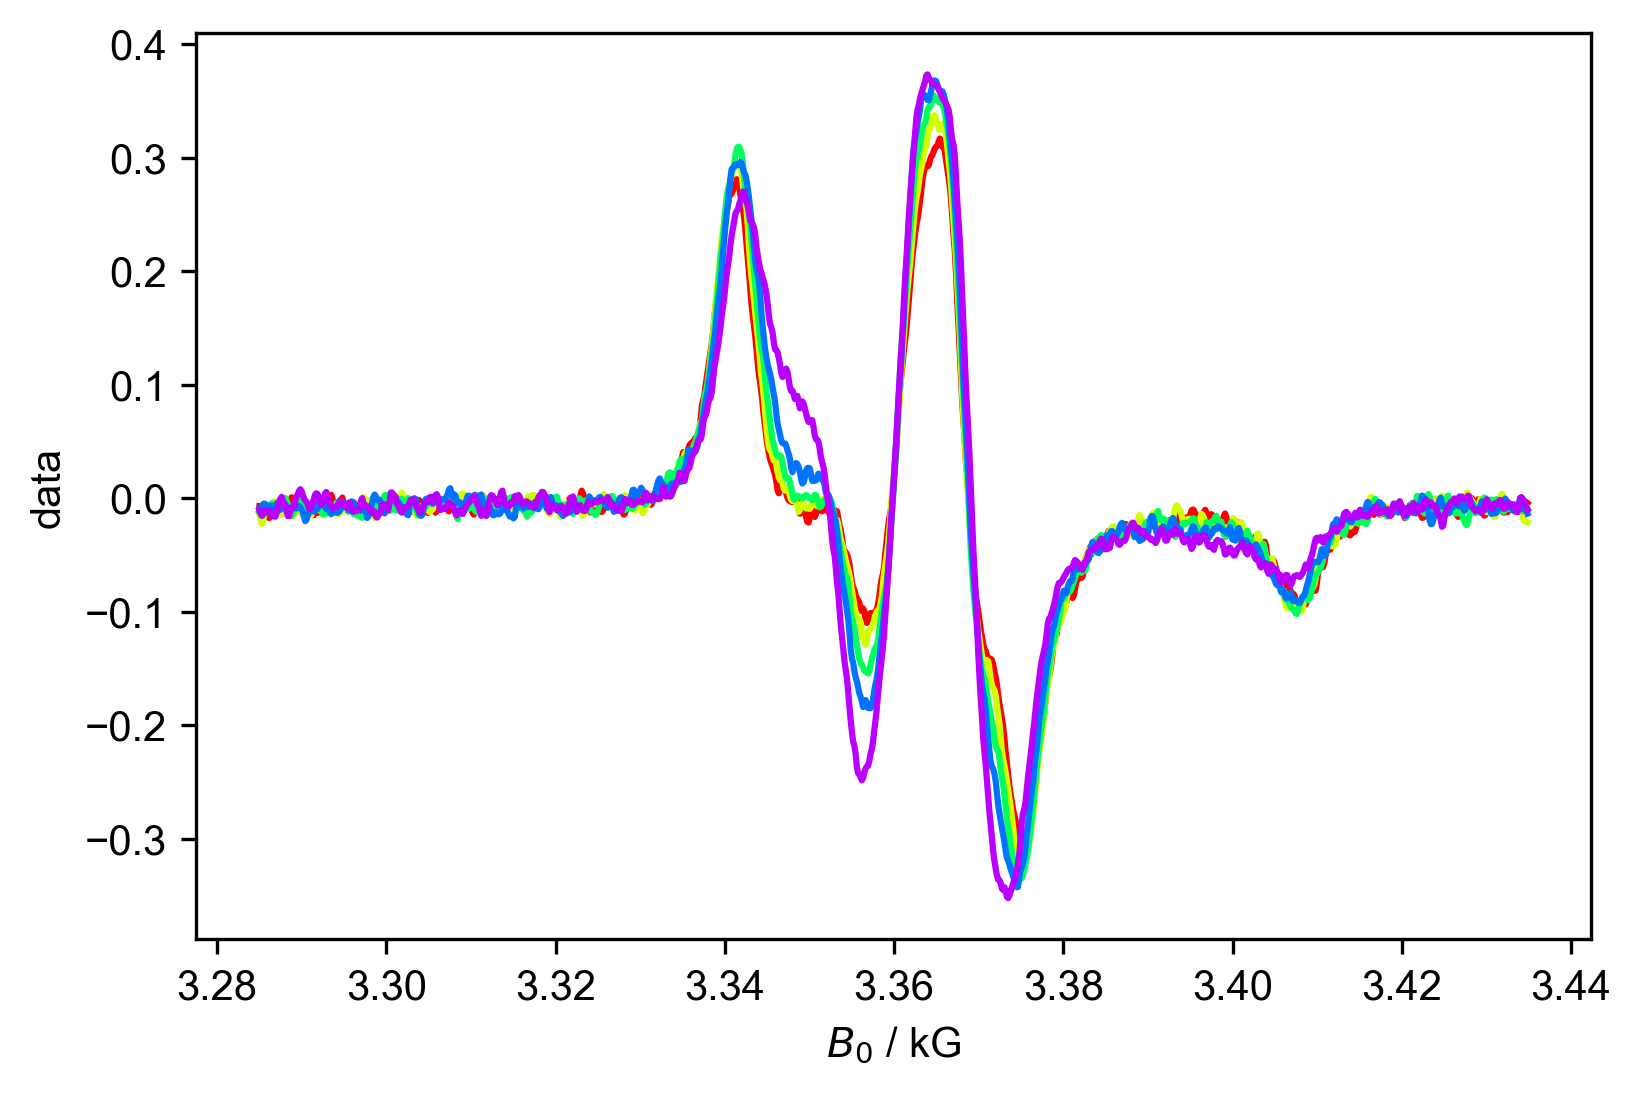

In [16]:
figure(dpi=300)
d_reheating['Temperature':(None,260)]

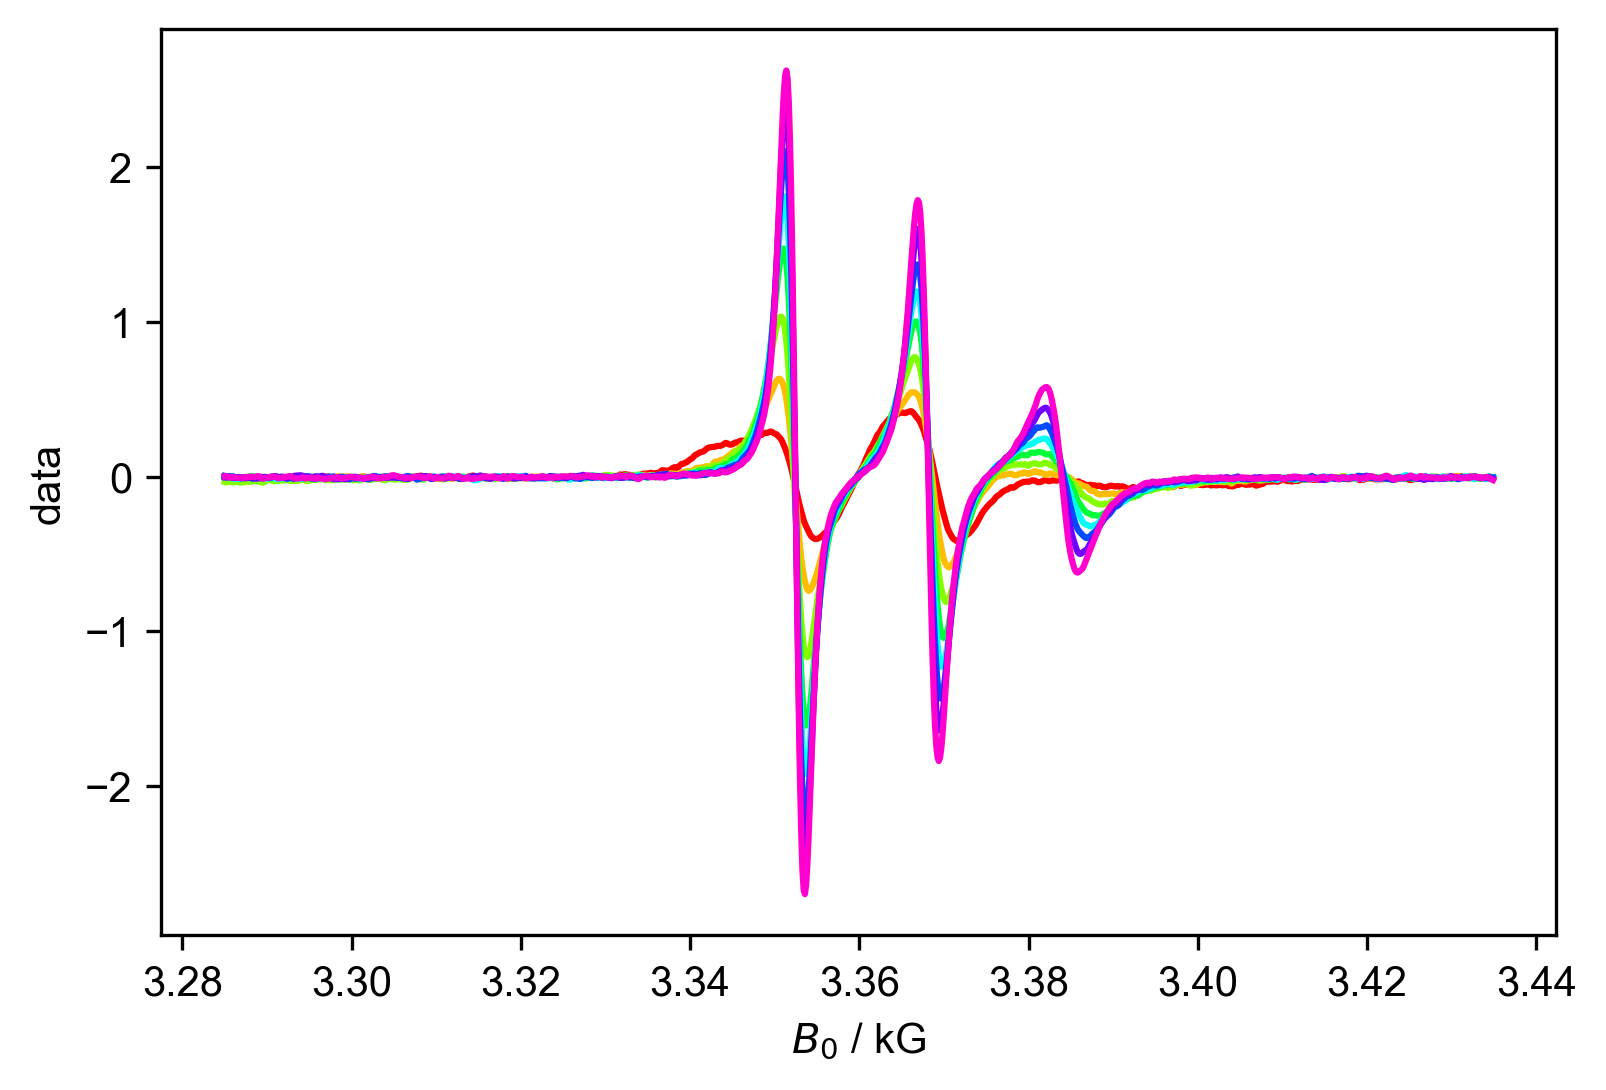

In [17]:
figure(dpi=300)
d_reheating['Temperature':(260,None)]

RS: Below transition

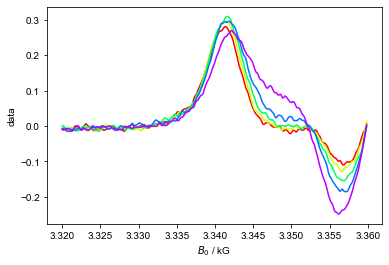

In [18]:
d_reheating['Temperature':(None,260)]['$B_0$':(3320,3360)] # peak A below transition

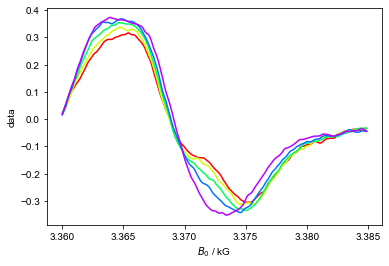

In [19]:
d_reheating['Temperature':(None,260)]['$B_0$':(3360,3385)] # peak B below transition

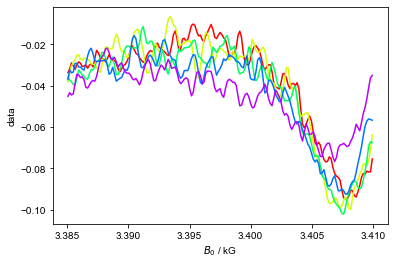

In [20]:
d_reheating['Temperature':(None,260)]['$B_0$':(3385,3410)] # peak C below transition

RS: above transition

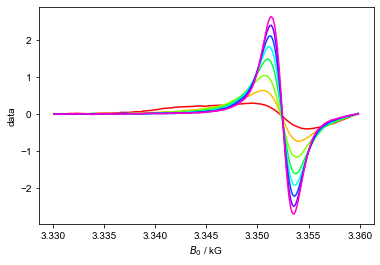

In [21]:
d_reheating['Temperature':(260,None)]['$B_0$':(3330,3360)] # peak A above transition

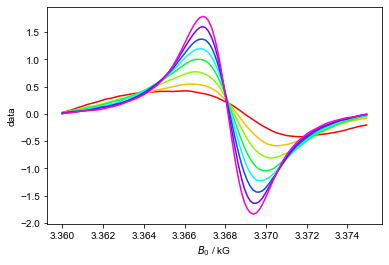

In [22]:
d_reheating['Temperature':(260,None)]['$B_0$':(3360,3375)] # peak B above transition

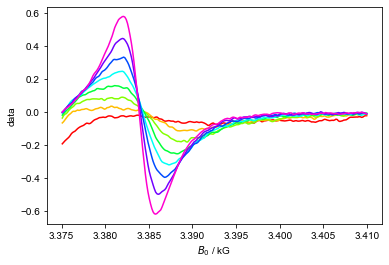

In [23]:
d_reheating['Temperature':(260,None)]['$B_0$':(3375,3410)] # peak C above transition

#### RS: below transition

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.5789897194508207e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.5789897194508207e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.5789897194508207e-09


... (16 outputs left out)

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.5789897194508207e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


correlation time is 1.5789897194508207e-09
1: slice peak A
2: slice peak B
3: slice peak C
4: pub_fig



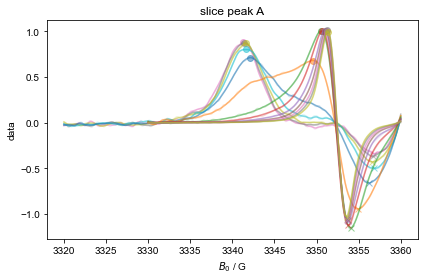

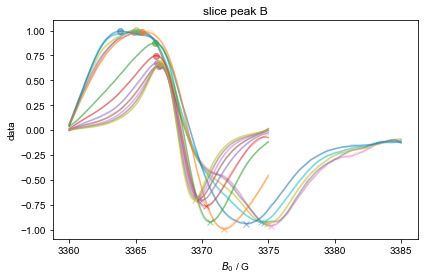

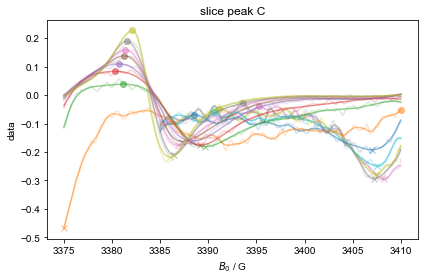

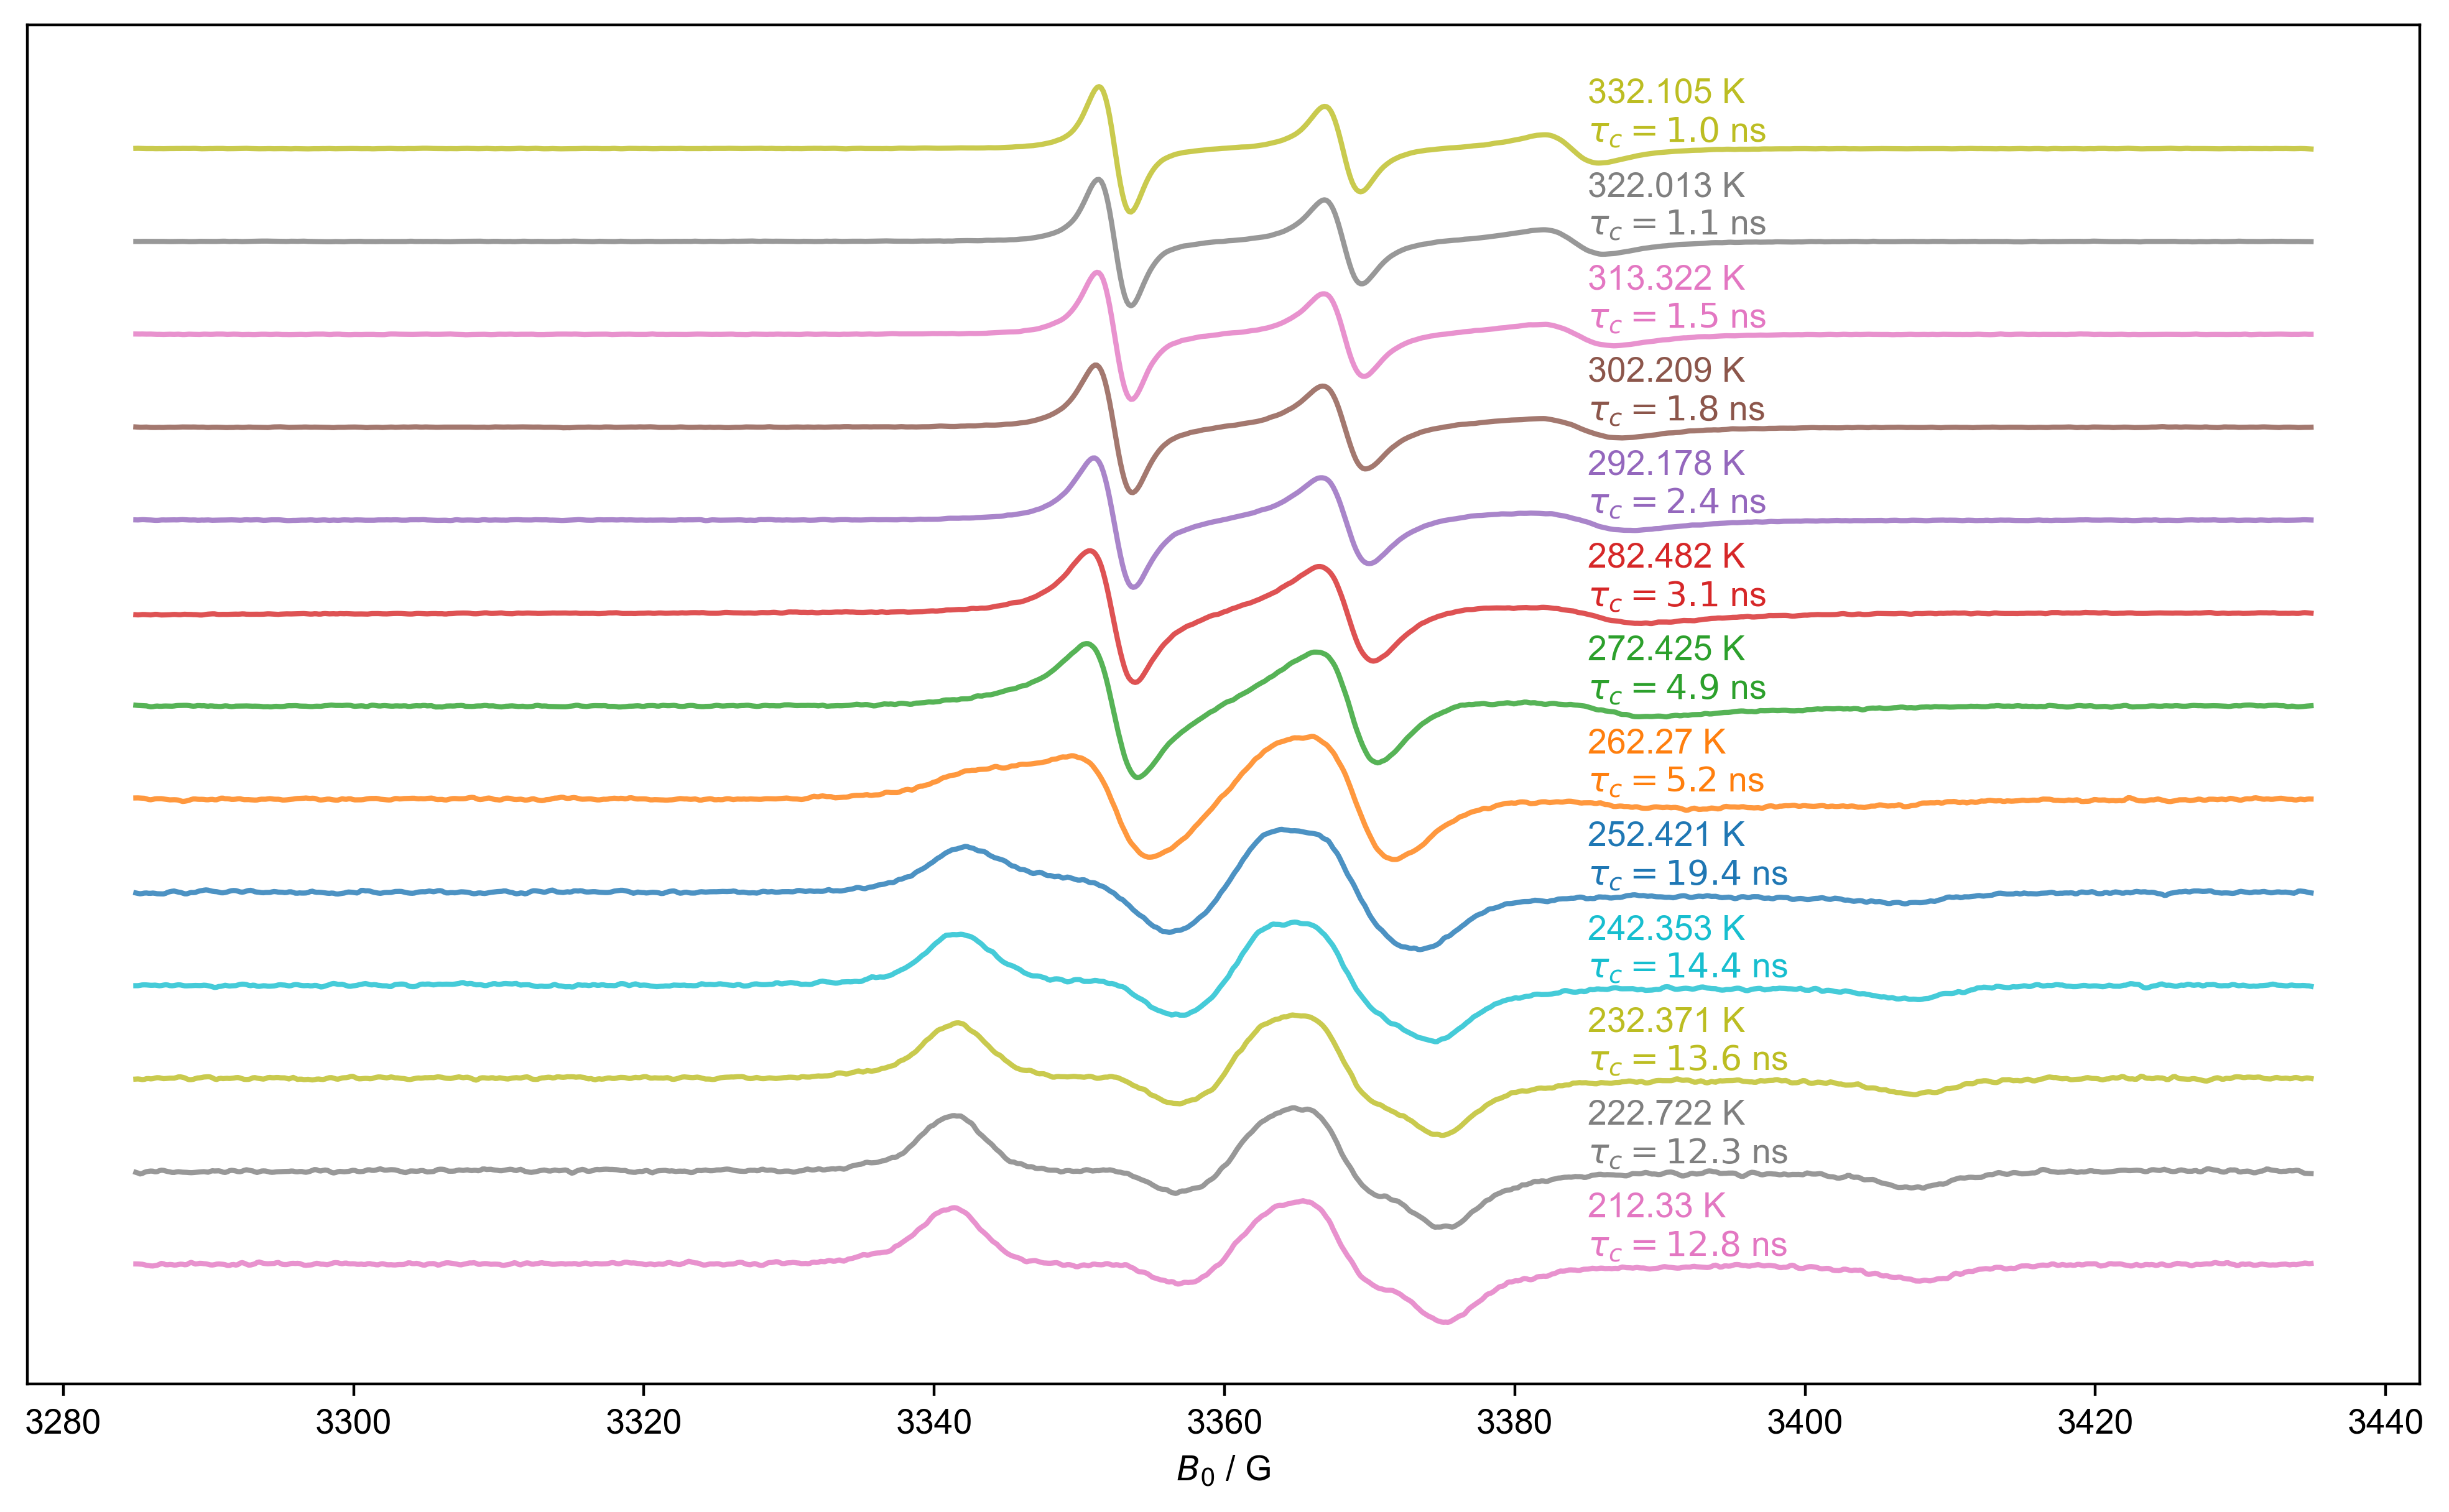

In [24]:
all_data_reheating= d_reheating['Temperature':(None,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
correlation_time_reheating = {}
with figlist_var() as fl: ### why with???
    for this_temp in all_data_reheating['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_reheating["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data_reheating = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 260:
            peak_A_range = (3330,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3375,3410)
#         elif this_temp >= 263:
            
        else:
            peak_A_range = (3320,3360)
            peak_B_range = (3360,3385)
            peak_C_range = (3385,3410)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=2e-3)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_reheating[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_reheating[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data_reheating[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_reheating[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data_reheating[peak_name+'maxB0'],peak_data_reheating[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data_reheating[peak_name+'minB0'],peak_data_reheating[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_reheating = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data_reheating)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_reheating[label_str] = tau_c_reheating 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c_reheating/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [25]:
correlation_time_reheating

{'212.33': 1.2788298436874976e-08,
 '222.722': 1.2319302475764222e-08,
 '232.371': 1.3593218556109347e-08,
 '242.353': 1.4394255332669866e-08,
 '252.421': 1.9387549001592544e-08,
 '262.27': 5.191462572507471e-09,
 '272.425': 4.864176585737424e-09,
 '282.482': 3.052181010770808e-09,
 '292.178': 2.356159016777562e-09,
 '302.209': 1.815807883894698e-09,
 '313.322': 1.4775117107931998e-09,
 '322.013': 1.1300483820754107e-09,
 '332.105': 9.681896934949982e-10}

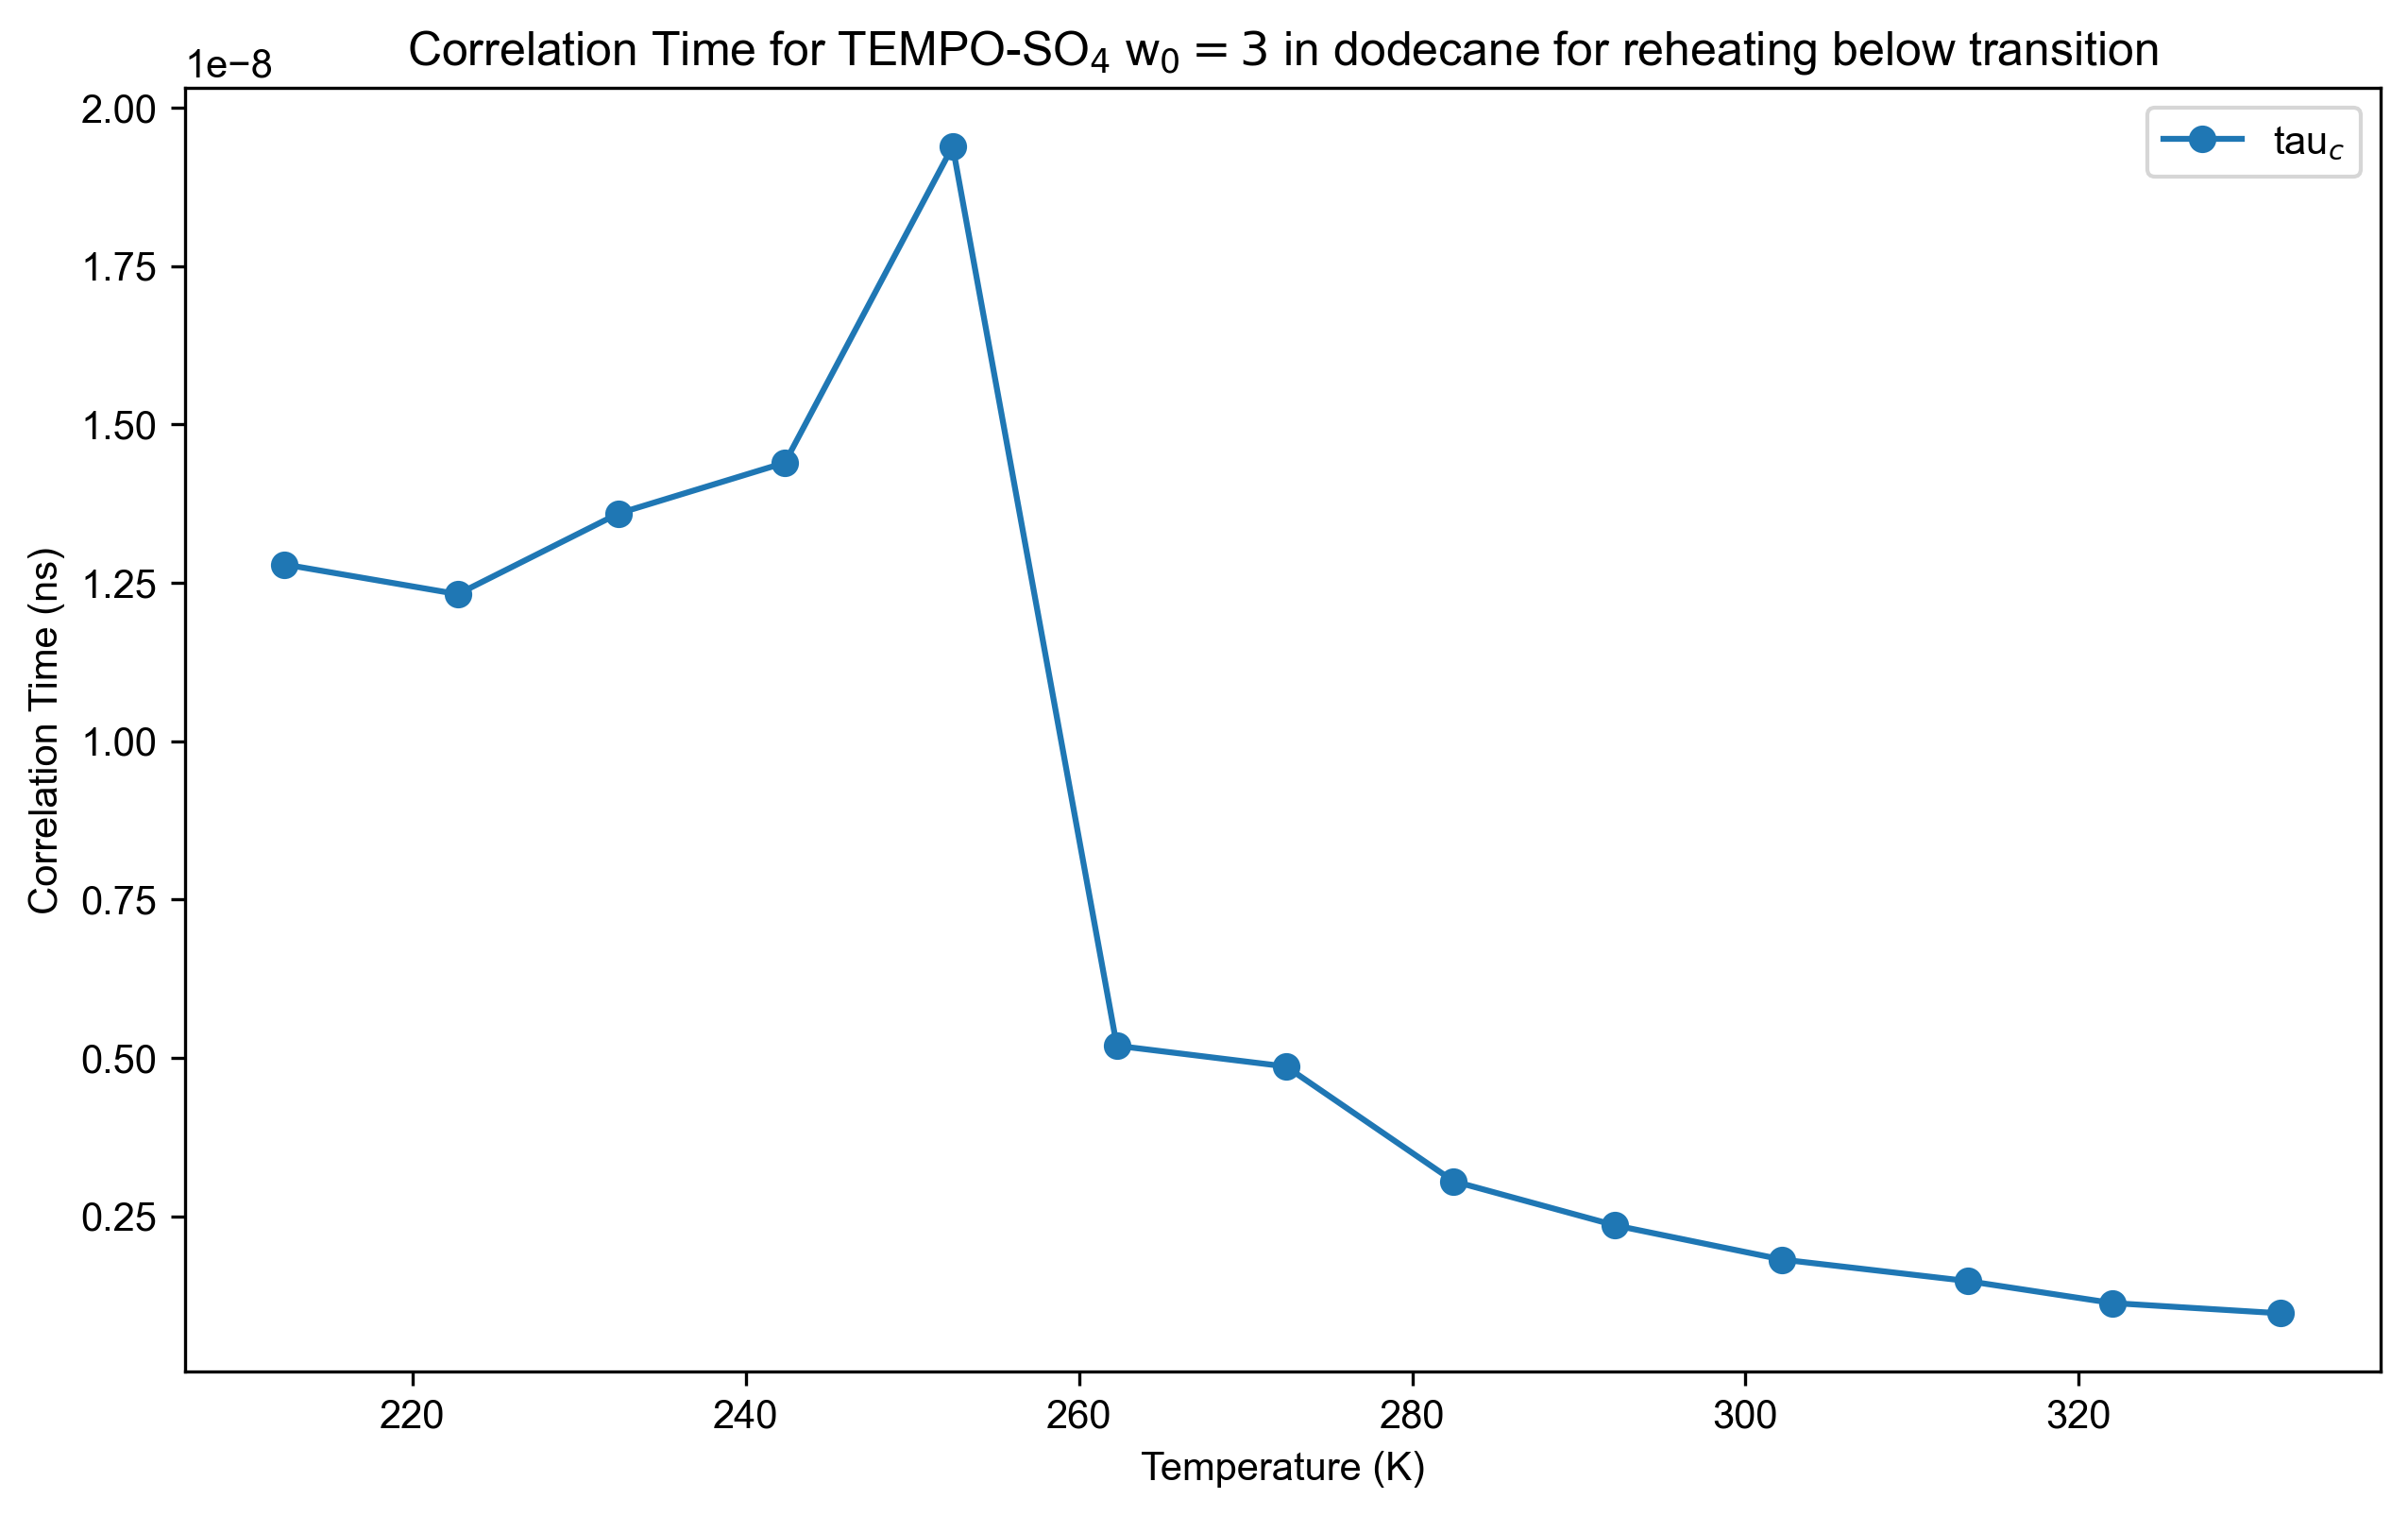

In [26]:
temp_reheating= [float(temp) for temp in correlation_time_reheating.keys()]
tau_reheating= list(correlation_time_reheating.values())
figure(dpi=300, figsize=(10,6))
plot(temp_reheating, tau_reheating, linestyle='-',  marker='o', label="tau$_c$")
legend()
plt.xlabel('Temperature (K)')
plt.ylabel('Correlation Time (ns)')
plt.title('Correlation Time for TEMPO-SO$_4$ w$_0=3$ in dodecane for reheating below transition')
plt.show()

#### RS: above transition 

c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

correlation time is 1.2832471520692687e-08
correlation time is 4.906405045922324e-09
correlation time is 3.071289045204519e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

correlation time is 2.2486957136765453e-09
correlation time is 1.7296288688212328e-09
correlation time is 1.441633741102513e-09


c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(

correlation time is 1.2139441617903513e-09
correlation time is 9.696769796754099e-10
1: slice peak A
2: slice peak B
3: slice peak C
4: pub_fig



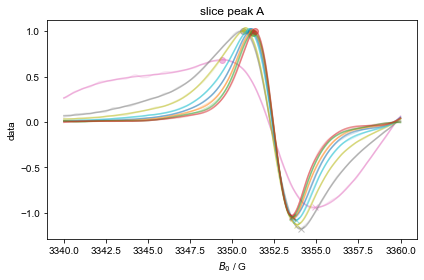

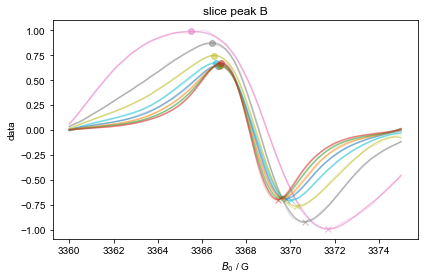

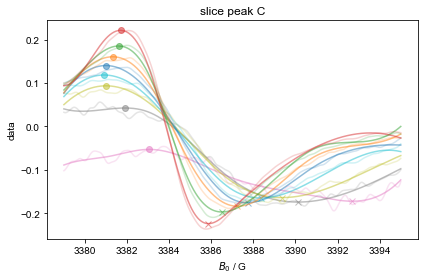

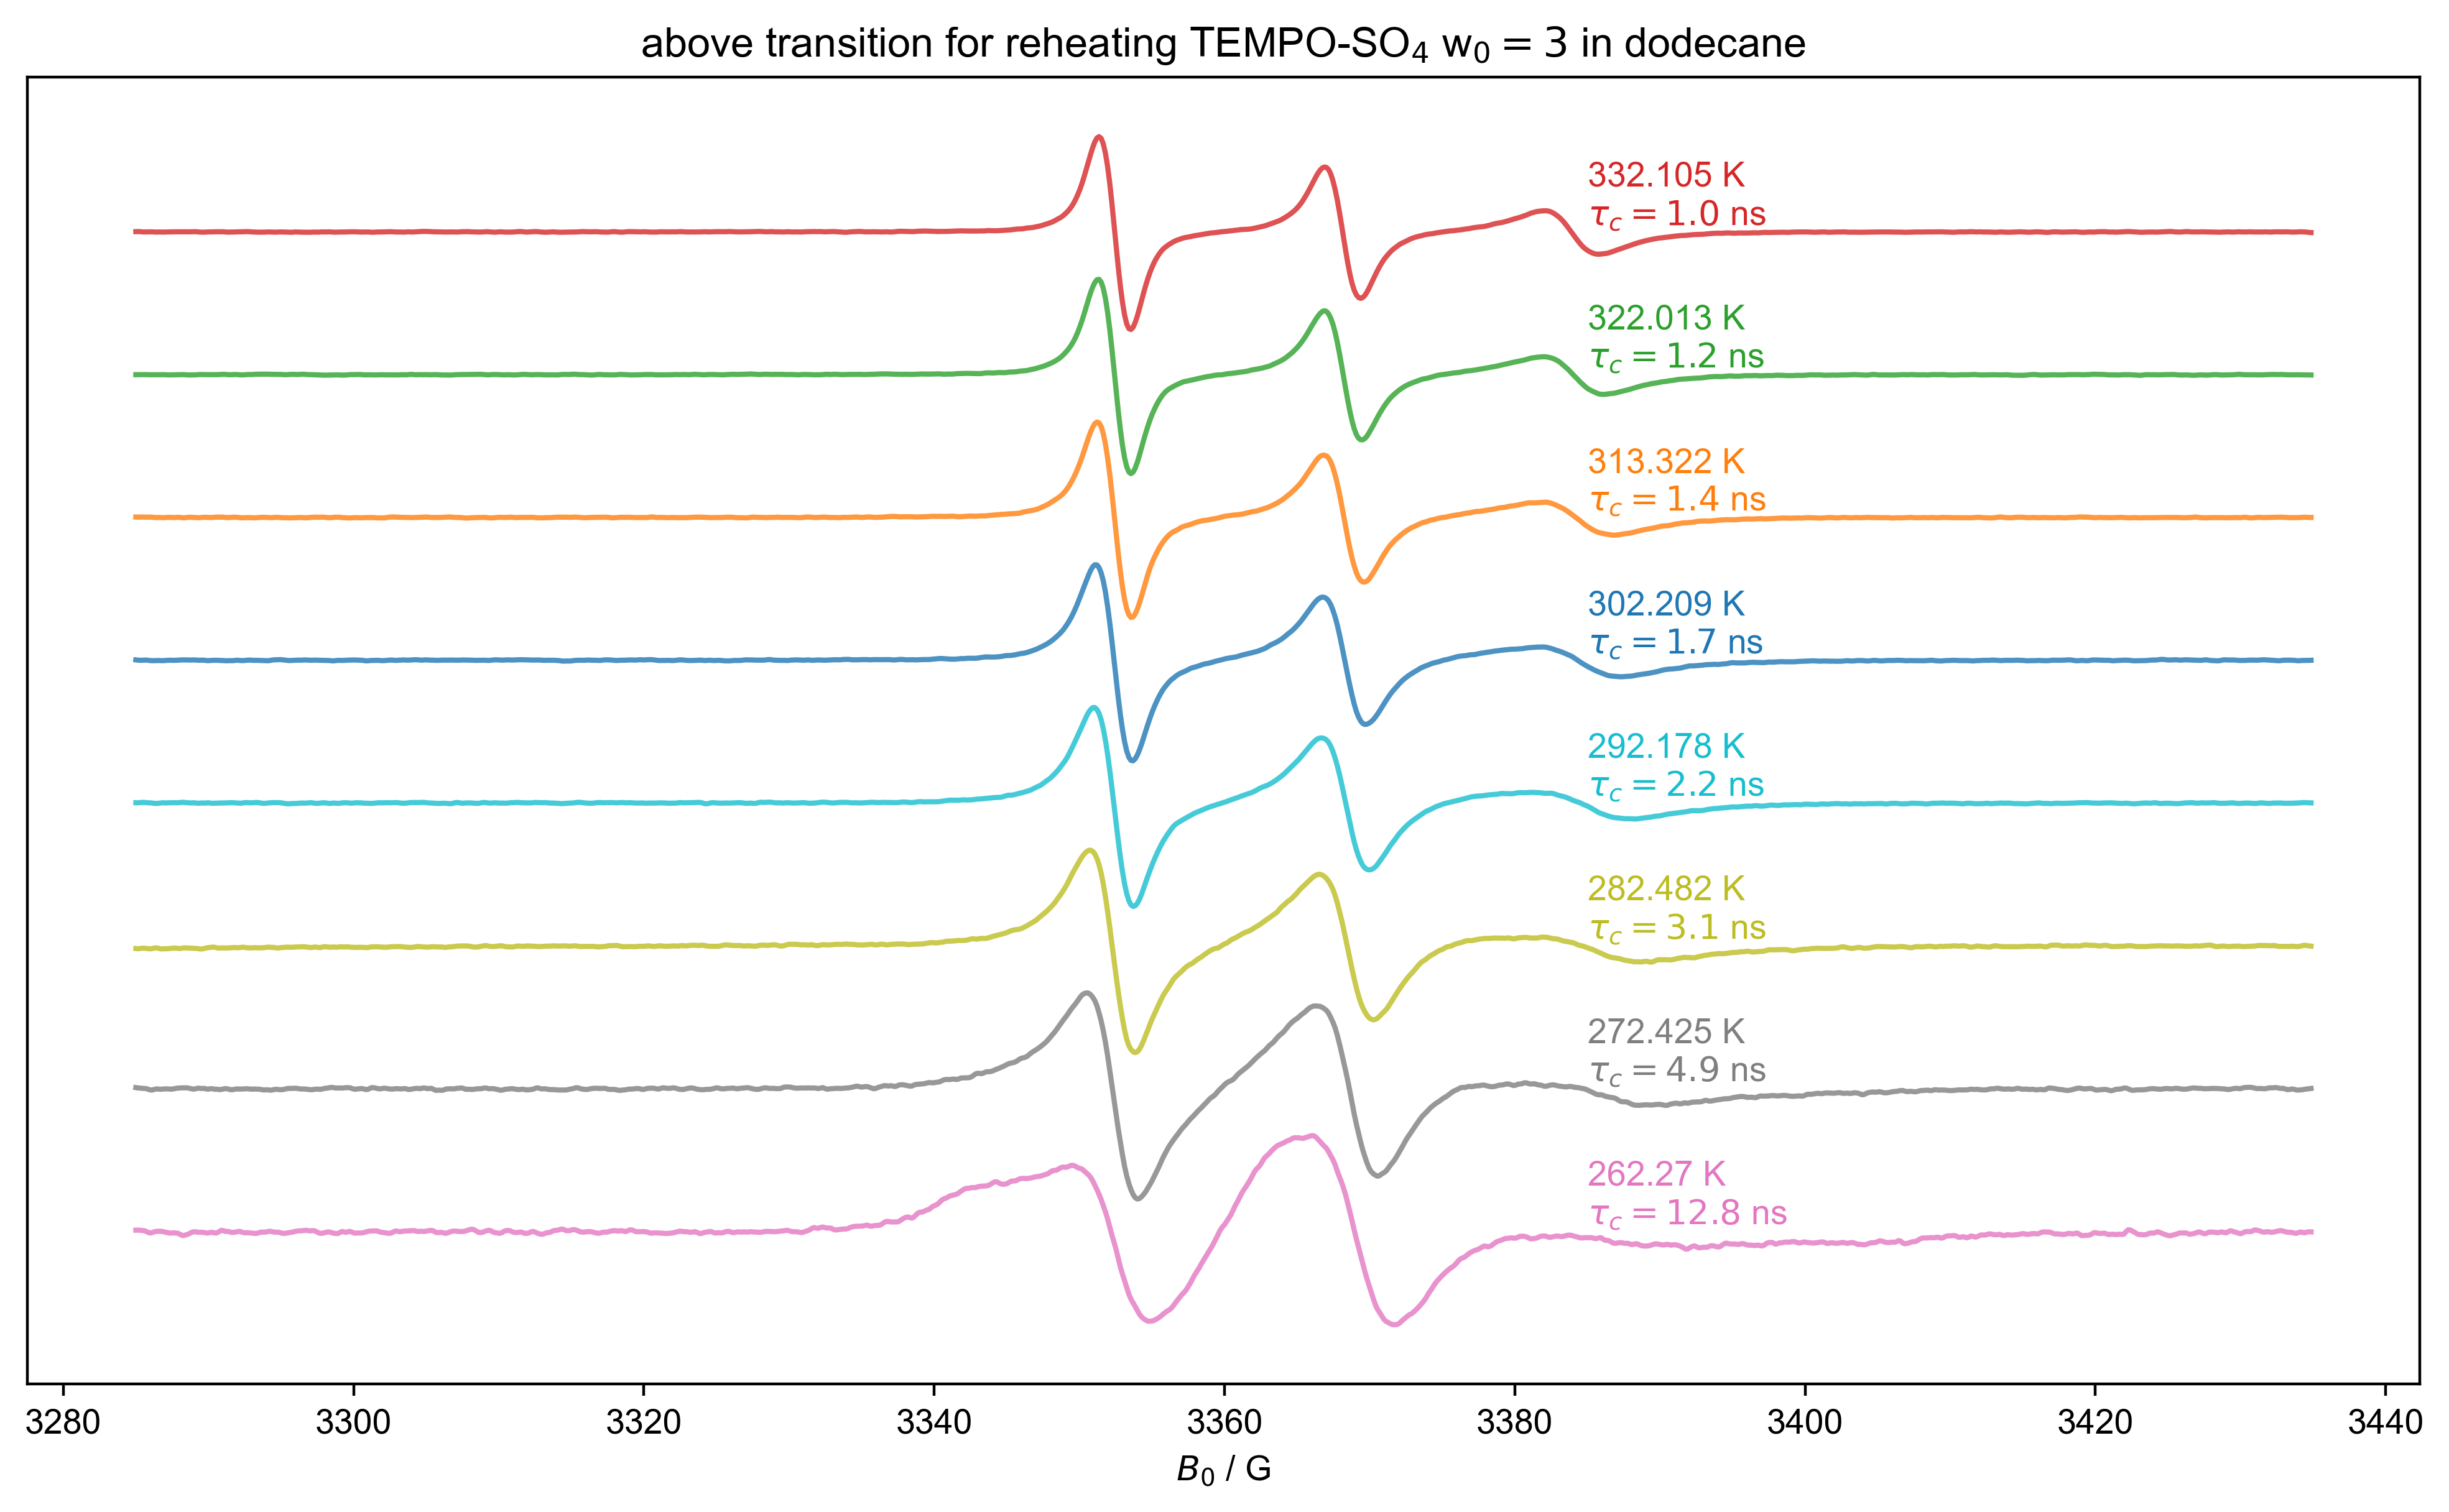

In [38]:
all_data_reheating= d_reheating['Temperature':(260,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data_reheating['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_reheating["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        
        peak_data_reheating = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 260:
            peak_A_range = (3340,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3379,3395)
#         elif this_temp >= 263:
            
        else:
            peak_A_range = (3320,3360)
            peak_B_range = (3360,3385)
            peak_C_range = (3385,3410)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=2e-3)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_reheating[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_reheating[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data_reheating[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_reheating[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data_reheating[peak_name+'maxB0'],peak_data_reheating[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data_reheating[peak_name+'minB0'],peak_data_reheating[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_reheating = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data_reheating)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c_reheating)
        correlation_time_reheating[label_str] = tau_c_reheating 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c_reheating/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('above transition for reheating TEMPO-SO$_4$ w$_0=3$ in dodecane')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [30]:
correlation_time_reheating

{'212.33': 1.2788298436874976e-08,
 '222.722': 1.2319302475764222e-08,
 '232.371': 1.3593218556109347e-08,
 '242.353': 1.4394255332669866e-08,
 '252.421': 1.9387549001592544e-08,
 '262.27': 1.2832471520692687e-08,
 '272.425': 4.906405045922324e-09,
 '282.482': 3.071289045204519e-09,
 '292.178': 2.2486957136765453e-09,
 '302.209': 1.7296288688212328e-09,
 '313.322': 1.441633741102513e-09,
 '322.013': 1.2139441617903513e-09,
 '332.105': 9.696769796754099e-10}

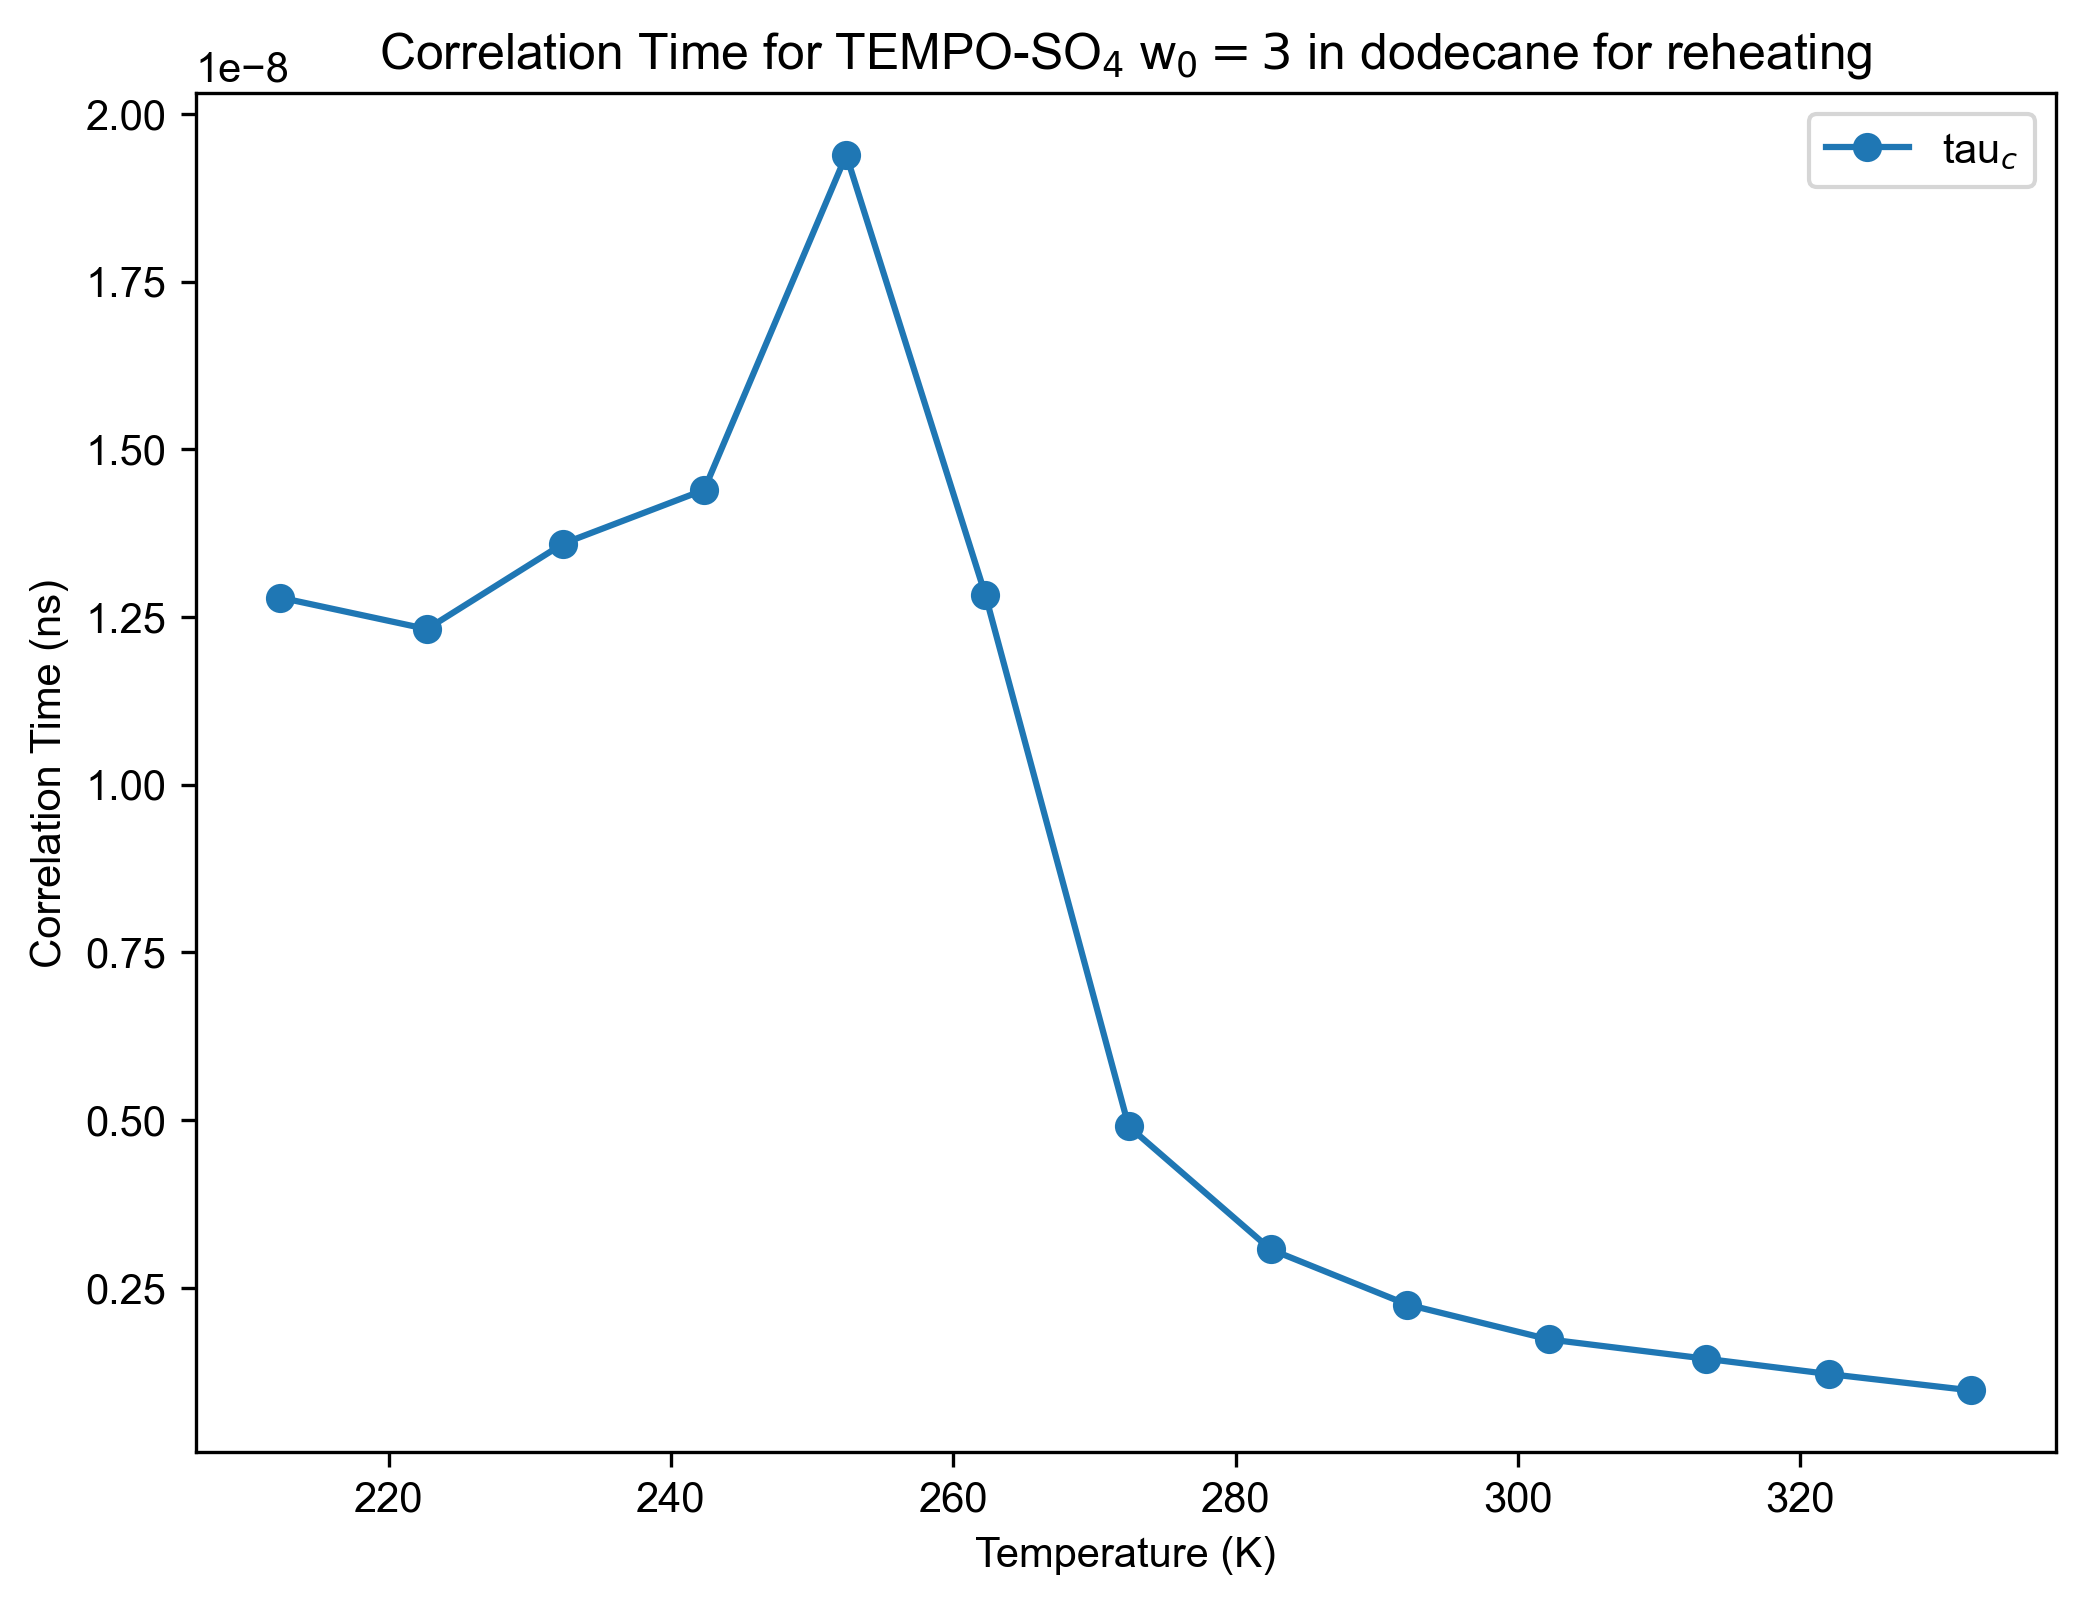

In [31]:
temp_reheating= [float(temp) for temp in correlation_time_reheating.keys()]
tau_reheating= list(correlation_time_reheating.values())
figure(dpi=300, figsize=(8,6))
plot(temp_reheating, tau_reheating, linestyle='-',  marker='o', label="tau$_c$")
legend()
plt.xlabel('Temperature (K)')
plt.ylabel('Correlation Time (ns)')
plt.title('Correlation Time for TEMPO-SO$_4$ w$_0=3$ in dodecane for reheating')
plt.show()

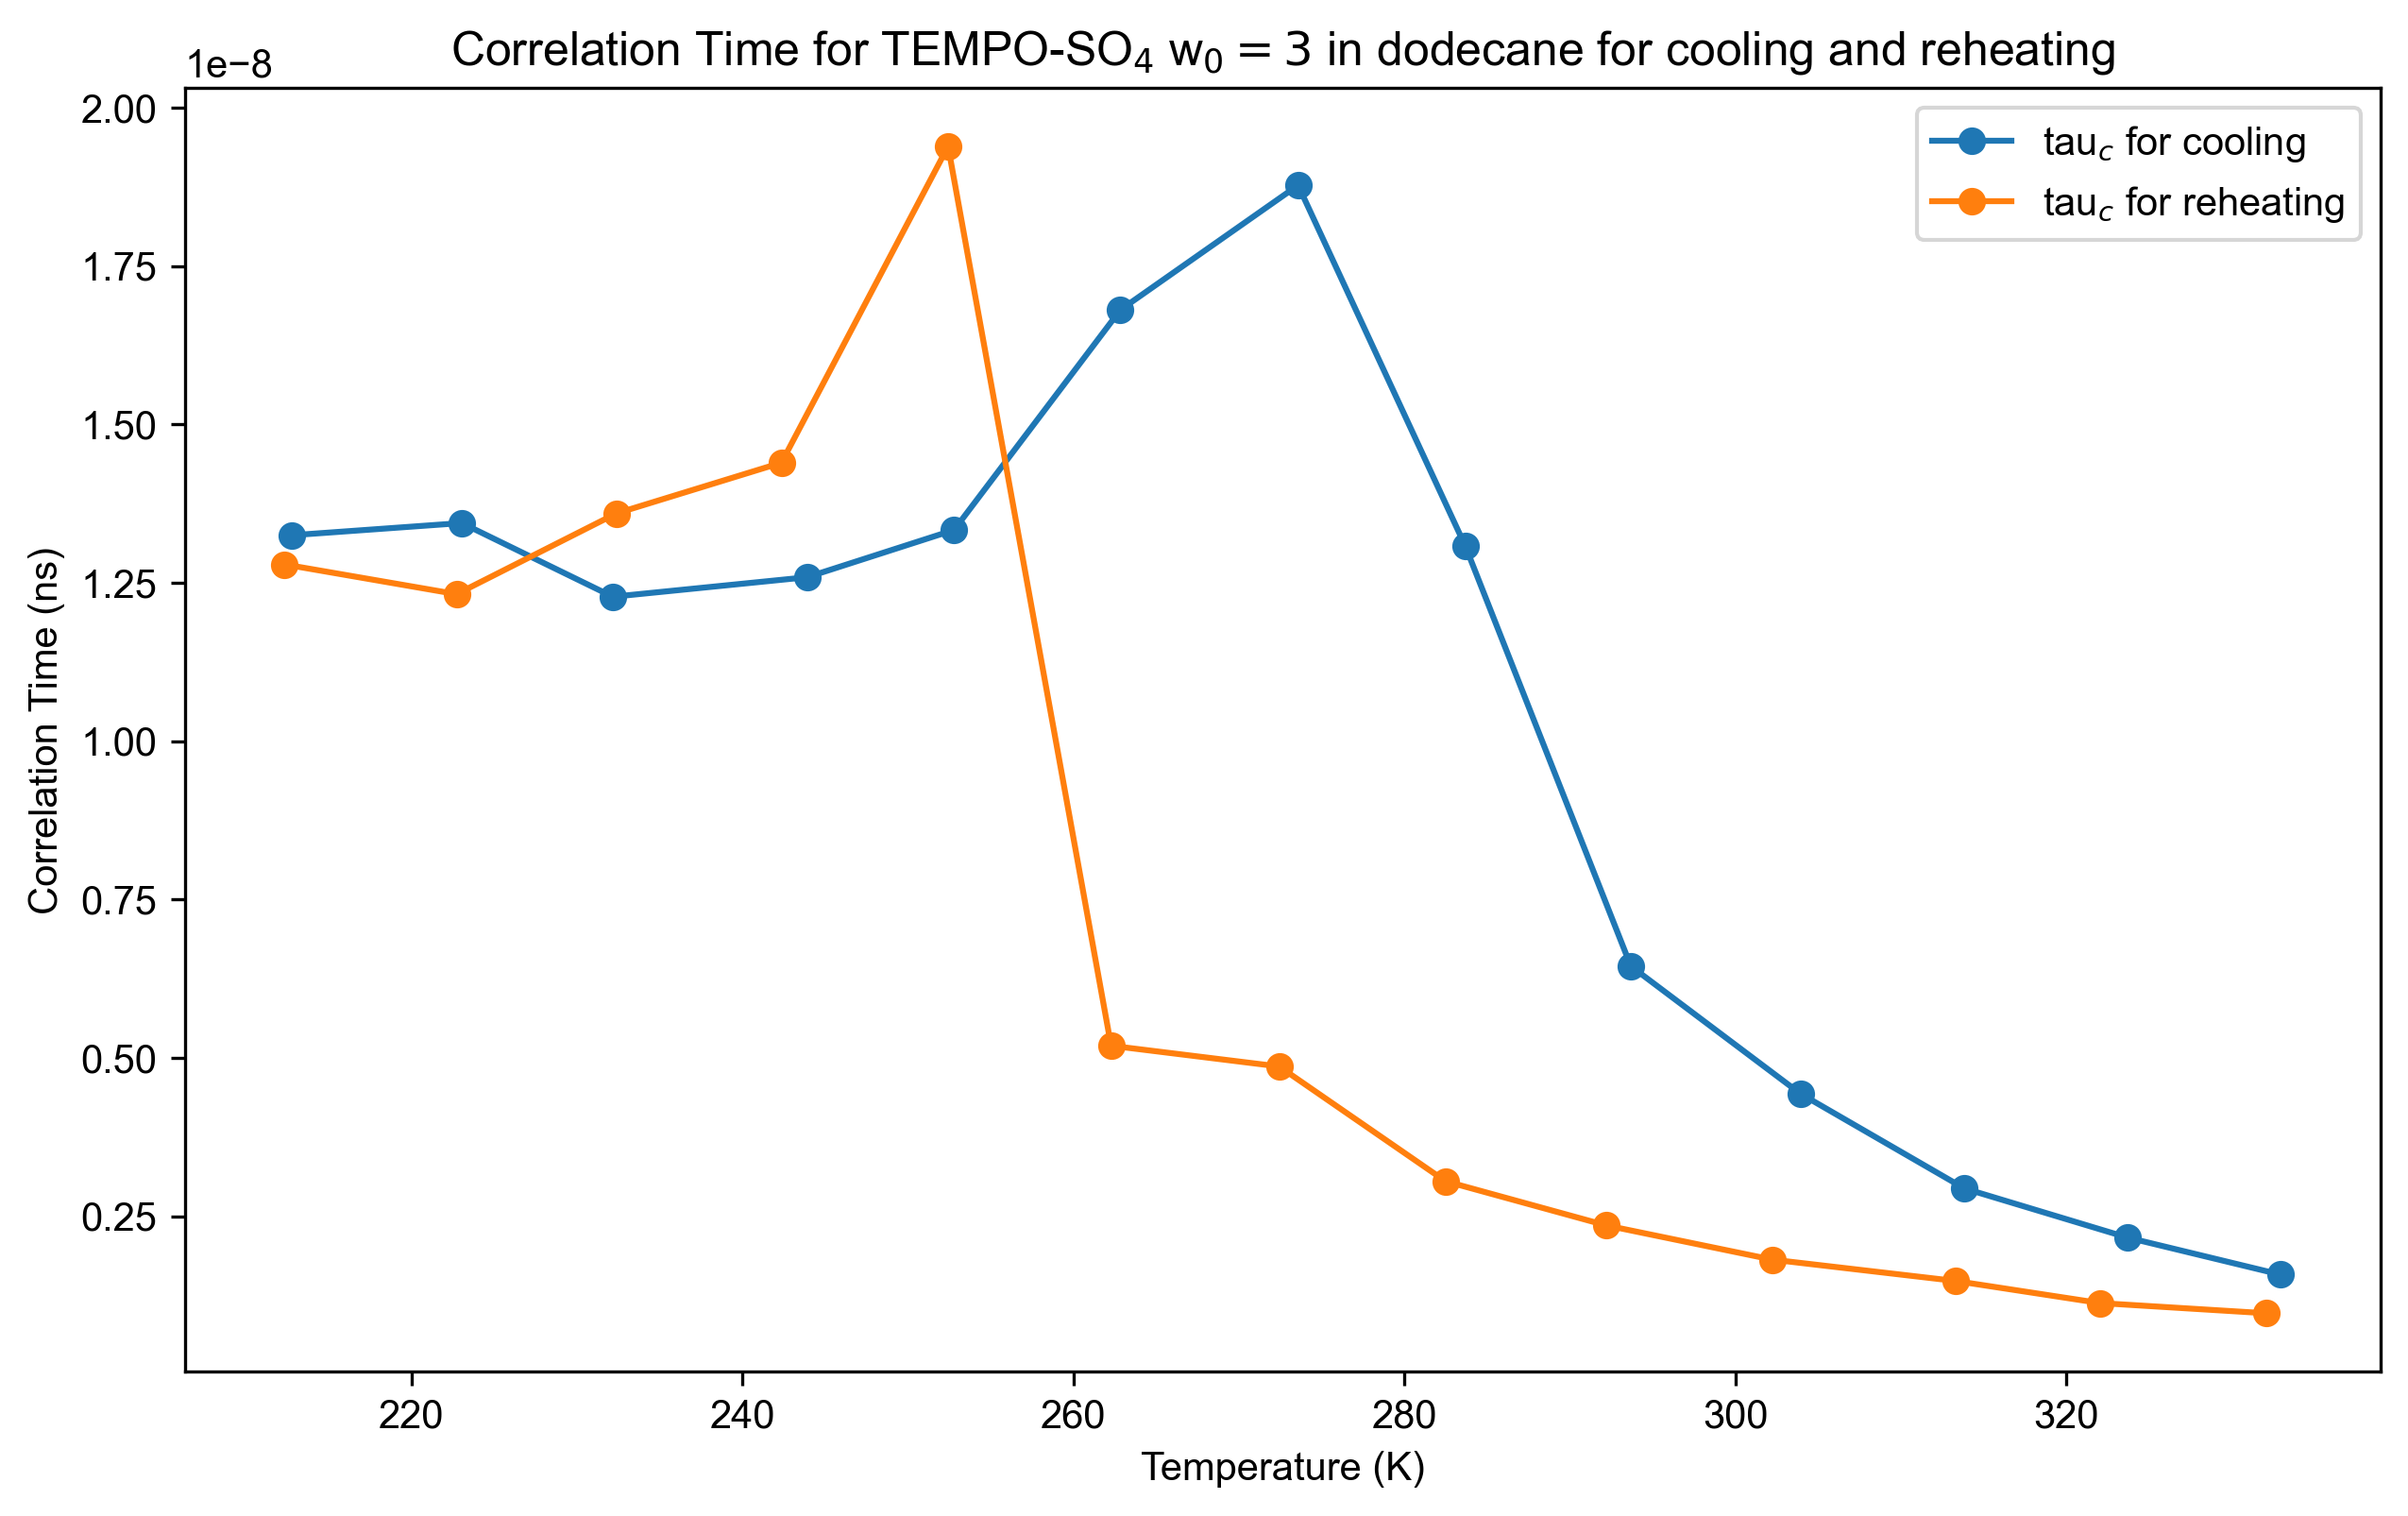

In [27]:
figure(dpi=300, figsize=(10,6))
plot(temp, tau, linestyle='-',  marker='o', label="tau$_c$ for cooling")
plot(temp_reheating, tau_reheating, linestyle='-',  marker='o', label="tau$_c$ for reheating")
legend()
plt.xlabel('Temperature (K)')
plt.ylabel('Correlation Time (ns)')
plt.title('Correlation Time for TEMPO-SO$_4$ w$_0=3$ in dodecane for cooling and reheating')
plt.show()

RS: I was trying to plot all temperature in one plot with tau values, but I was getting error for float and list type values. So I just leave it here by commented out.

In [33]:
# all_data= d_cooling['Temperature':(None,None)]
# with figlist_var() as fl: ### why with???
#     for this_temp in all_data['Temperature']:
#         this_color = next(colors)
#         label_str = str(this_temp)
# #         d = all_data["Temperature": this_temp]
# #         d /= d.max().item() 
# #         temp= [float(temp) for temp in correlation_time.keys()]
# #         tau= list(correlation_time.values())
#         fl.next('pub_fig',figsize=(10,16/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
#         fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
#         plt.gca().text(
#                 3385,
#                 x_counter,
#                 temp+f' K\n$\\tau_c={tau/1e-9:0.1f}$ ns',
#                 transform=plt.gca().transData,
#                 va='bottom',
#                 ha='left',
#                 color=this_color,
#                 )
#         x_counter += 1.5
#         j_counter += 1
# #     fl.next('pub_fig')
#     plt.title('')
#     plt.ylabel('')
#     plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
#                           labelleft=False, labelbottom=True,
#                           labelright=False)

In [34]:
# It was from AB's code and I kept it by commented out.

# R_h = 3.35e-9/2
# T = 273+20
# eta = 0.91e-3 # 1 cP = 1e-3 Pa*s
# 4*pi*R_h**3*eta/(3*k_B*T)/1e-9

In [35]:
(0.29+1.1)/2

In [36]:
3.35/2

In [37]:
0.175+1.5